# Лабораторна робота №3. Розпізнавання тексту з застосуванням ШІ

**Студент:** Скиданчук М.Д.  
**Варіант:** 6  
**Набір:** Perestoroha OCR · **Інструменти:** EasyOCR, PaddleOCR · **Чинник:** зниження роздільності

## 0. Налаштування і персональні параметри

In [1]:
import os, re, time, hashlib, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageDraw, ImageFont
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")

# ---- персональні параметри ----
STUDENT = "Скиданчук М.Д."
VARIANT = 6
STUDENT_ID = 962
SEED = 1000 * VARIANT + STUDENT_ID   # 6962
rng = np.random.default_rng(SEED)

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

def stamp(ax, title):
    """Заголовок графіка з персональним підписом студента."""
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

print(STUDENT, VARIANT, SEED)

Скиданчук М.Д. 6 6962


## 1. Гіпотези (записано до запуску розпізнавання, 07.11.2026)

Прогнози сформульовано до першого запуску EasyOCR і PaddleOCR на даних. Чернетку підготовлено разом з ШІ-асистентом, студент її розглянув і погодив; оцінка («підтверджено / спростовано») буде додана після експериментів.

| № | Гіпотеза (прогноз) | Обґрунтування | Оцінка |
|---|---|---|---|
| Г1 | На картках Perestoroha без зниження роздільності (×1) CER обох інструментів не менший за 0,60; PaddleOCR не буде кращим за EasyOCR. | Інструменти навчені на друкованому тексті, а картки рукописні зі старими літерами (ѣ, ъ, титла). | — |
| Г2 | При зниженні роздільності ×4 CER обох інструментів не менший за 0,90; найстрімкіше зростання між ×1 і ×2,5. Поріг 10% перевищується вже на ×1 (плато одразу високо). | При ×4 картка має ~290×188 пікселів, штрихи рукопису зливаються. | — |
| Г3 | Розширена нормалізація історичних графем (ѣ→і, ъ→∅, ѡ→о тощо, без титл і наголосів) знизить CER лише на 2–5 процентних пунктів. | Основна помилка пов'язана з рукописом, а не з окремими старими літерами. | — |
| Г4 | На фото меморіальної дошки / старого напису CER буде у 2–3 рази нижчим, ніж на картках Perestoroha. | Друкований або вирізаний текст ближчий до даних, на яких навчені моделі. | — |
| Г5 | На фото власної рукописної сторінки CER буде щонайменше у 10 разів вищим за CER на синтетичному друкованому тексті (його очікую ≤ 0,05 на ×1). | Рукопис, тіні й кут зйомки (domain gap). | — |
| Г6 | Бінаризація Оцу погіршить CER обох інструментів не менш ніж на 5 п.п.; збільшення ×2 з медіанним фільтром покращить результат. | Нейромережі навчені на зображеннях у відтінках сірого; бінаризація руйнує тонкі штрихи. | — |
| Г7 | На CPU PaddleOCR опрацьовує зображення швидше за EasyOCR (час ≤ 0,7 від часу EasyOCR). | Легший конвеєр детекції й розпізнавання. | — |


## 2. Відкритий набір Perestoroha OCR: огляд структури

In [2]:
from datasets import load_dataset

ds = load_dataset("lang-uk/perestoroha-ocr")
print(ds)                       # спліти, кількість записів, назви полів
for name, part in ds.items():
    print(name, part.features)


DatasetDict({
    train: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 278
    })
    validation: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 122
    })
    test: Dataset({
        features: ['id', 'image', 'transcription', 'card_num_primary', 'card_num_secondary', 'card_num_tertiary', 'card_num_notes', 'source_city', 'source_date', 'source_reference', 'notes', 'reviewed_at'],
        num_rows: 30
    })
})
train {'id': Value('string'), 'image': Image(mode=None, decode=True), 'transcription': Value('string'), 'card_num_primary': Value('string'), 'card_num_secondary': Value('string'), 'card_num_tertiary': Value('s

In [3]:
# перший запис: що лежить у кожному полі
split = list(ds.keys())[0]
sample = ds[split][0]
for k, v in sample.items():
    if hasattr(v, "size"):                     # зображення PIL
        print(k, "-> image", v.size, v.mode)
    else:
        print(k, "->", repr(v)[:300])
sample[[k for k, v in sample.items() if hasattr(v, "size")][0]].save("data/perestoroha_0.png")


id -> 'Auto-Color0002/182'
image -> image (1160, 752) RGB
transcription -> 'пан воєвода кієвскій для коней\r\nєго себѣ слалъ с килькома сты червоных\r\nЛьвів, 1605-1606, Перест. 38'
card_num_primary -> '10'
card_num_secondary -> None
card_num_tertiary -> '153'
card_num_notes -> '10 top-left in pencil (circled); 153 bottom-right in pencil'
source_city -> 'Львів'
source_date -> '1605-1606'
source_reference -> 'Перест. 38'
notes -> "Second line opens with 'ето' as written (likely scribe's form of 'єго'); 'сты' written with titlo-like horizontal bar above but treated as plain letters per preset rules."
reviewed_at -> '2026-05-06T18:54:16.666799+00:00'


## 3. Нормалізація тексту та метрики CER / WER

**Формули.** Відстань Левенштейна рахується за символами (CER) і за словами (WER):
CER = (S + D + I) / N, де S, D, I — заміни, видалення, вставлення, N — довжина еталону в символах (для WER — у словах).
CER може перевищувати 1, якщо інструмент вставив багато зайвого.

**Усереднення.** Для кривих стійкості та бутстрепу використовується *макроусереднення* (середнє CER окремих зразків, кожен зразок має однакову вагу); у підсумкових таблицях додатково можна наводити мікро-CER (сума помилок за всіма зразками, поділена на сумарну довжину еталонів).

**Правила нормалізації** (однакові для всіх інструментів і наборів):
1. Unicode NFC (літера «й», «ї» — один символ).
2. Усі апострофи (’ ʼ ` ´ ′ ‘) зводяться до `'`; усі види тире (– — ‒ ― −) до `-`; лапки („ “ ” « » ‟) до `"`.
3. Послідовності пробілів і переноси рядків замінюються одним пробілом.
4. Регістр і пунктуація **зберігаються** для синтетичних і відкритих даних (для пунктуації втрачається інформація, а еталон її має). Для власних фото рукопису, написаного великими літерами, порівняння **без урахування регістру** (`fold=True`) — зафіксоване рішення.
5. **Розширена нормалізація історичних графем** (`hist=True`, особливість варіанта 6): ѣ→і, ъ→∅, ѡ/ѻ/ѽ→о, ѧ/ѩ/ꙗ→я, ѫ/ѹ/ꙋ→у, ѥ→є, ѕ→з, ѵ→и, ѳ→ф, ѿ→от, ы→и, ѯ→кс, ѱ→пс; видалення комбінованих знаків (титла, наголоси) та дужок розкриття скорочень. Метрики з `hist=False` і `hist=True` порівнюються в розділі про особливість варіанта.

In [4]:
# ---- нормалізація ----
APOSTROPHES = "\u2019\u02bc`\u00b4\u2032\u2018"
DASHES = "\u2013\u2014\u2012\u2015\u2212"
QUOTES = "\u201e\u201c\u201d\u00ab\u00bb\u201f"

# історичні графеми -> сучасні (розширена нормалізація)
HIST_MAP = {
    "ѣ": "і", "Ѣ": "І", "ъ": "", "Ъ": "", "ѡ": "о", "Ѡ": "О", "ѻ": "о", "ѽ": "о",
    "ѧ": "я", "Ѧ": "Я", "ѩ": "я", "ꙗ": "я", "ѫ": "у", "ѹ": "у", "ꙋ": "у", "Ѹ": "У",
    "ѥ": "є", "ѕ": "з", "Ѕ": "З", "ѵ": "и", "Ѵ": "И", "ѳ": "ф", "Ѳ": "Ф",
    "ѿ": "от", "ы": "и", "Ы": "И", "ѯ": "кс", "ѱ": "пс",
}

def normalize(s, hist=False, fold=False):
    """Єдина нормалізація тексту перед обчисленням метрик."""
    s = unicodedata.normalize("NFC", s)
    for ch in APOSTROPHES:
        s = s.replace(ch, "'")
    for ch in DASHES:
        s = s.replace(ch, "-")
    for ch in QUOTES:
        s = s.replace(ch, '"')
    if hist:
        s = "".join(HIST_MAP.get(c, c) for c in s)
        # після NFC «й», «ї» є одним символом, тому видаляються лише титла, наголоси тощо
        s = "".join(c for c in s if unicodedata.category(c) != "Mn")
        s = re.sub(r"[()\[\]]", "", s)
    if fold:
        s = s.casefold()
    return re.sub(r"\s+", " ", s).strip()

# ---- метрики ----
def cer(gt, pred, **kw):
    g, p = normalize(gt, **kw), normalize(pred, **kw)
    return Levenshtein.distance(g, p) / max(len(g), 1)

def wer(gt, pred, **kw):
    g, p = normalize(gt, **kw).split(), normalize(pred, **kw).split()
    return Levenshtein.distance(g, p) / max(len(g), 1)

def cer_micro(pairs, **kw):
    """Мікроусереднений CER за списком пар (еталон, результат)."""
    errs = sum(Levenshtein.distance(normalize(g, **kw), normalize(p, **kw)) for g, p in pairs)
    total = sum(len(normalize(g, **kw)) for g, _ in pairs)
    return errs / max(total, 1)

def edit_ops(gt, pred, **kw):
    """Список операцій (op, символ еталону, символ результату): replace / delete / insert."""
    g, p = normalize(gt, **kw), normalize(pred, **kw)
    ops = []
    for tag, i1, i2, j1, j2 in Levenshtein.opcodes(g, p):
        if tag == "replace":
            ops += [("replace", g[i], p[j]) for i, j in zip(range(i1, i2), range(j1, j2))]
        elif tag == "delete":
            ops += [("delete", g[i], "") for i in range(i1, i2)]
        elif tag == "insert":
            ops += [("insert", "", p[j]) for j in range(j1, j2)]
    return ops

# ---- самоперевірка за прикладом з методички ----
assert abs(cer("інженерія даних", "інженерія даиих") - 1 / 15) < 1e-9     # CER = 1/15 ≈ 0,067
assert abs(wer("інженерія даних", "інженерія даиих") - 0.5) < 1e-9        # WER = 1/2
assert normalize("м’ята") == normalize("м'ята")                          # апострофи
assert normalize("рѣка ѿ", hist=True) == "ріка от"                       # історичні графеми
assert cer("Привіт", "ПРИВІТ", fold=True) == 0 and cer("Привіт", "ПРИВІТ") > 0
print("Перевірка метрик пройдена")

Перевірка метрик пройдена


## 4. Синтетичний набір з еталонною розміткою

Рядки вибираються з `corpus.txt` (Панас Мирний, «Хіба ревуть воли, як ясла повні?», остання цифра варіанта 6) за допомогою `numpy.random.default_rng([SEED, 1])`, тому набір повністю відтворюється за значенням SEED. Кожен рядок малюється окремим зображенням (чорний текст на білому тлі, шрифт і розмір вибираються за SEED). Еталон зберігається у `data/synthetic_gt.txt`, його хеш SHA-256 наводиться нижче й у звіті.

In [5]:
FONT_CANDIDATES = [
    # Windows
    "C:/Windows/Fonts/arial.ttf", "C:/Windows/Fonts/times.ttf", "C:/Windows/Fonts/calibri.ttf",
    "C:/Windows/Fonts/verdana.ttf", "C:/Windows/Fonts/tahoma.ttf",
    # Linux
    "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSerif.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf",
    "/usr/share/fonts/truetype/liberation/LiberationSerif-Regular.ttf",
    # macOS
    "/Library/Fonts/Arial.ttf",
]
FONTS = [p for p in FONT_CANDIDATES if os.path.exists(p)]
assert FONTS, "Не знайдено жодного шрифту з кирилицею: додайте шляхи до FONT_CANDIDATES"
print("Шрифти:", [os.path.basename(p) for p in FONTS])

N_LINES = 40
with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]
print("Рядків у корпусі після фільтра 20–70 символів:", len(corpus))

rng_text = np.random.default_rng([SEED, 1])
rng_font = np.random.default_rng([SEED, 2])
idx = np.sort(rng_text.choice(len(corpus), size=N_LINES, replace=False))
lines = [corpus[i] for i in idx]

with open("data/synthetic_gt.txt", "w", encoding="utf-8", newline="\n") as f:
    f.write("\n".join(lines) + "\n")
with open("data/synthetic_gt.txt", "rb") as f:
    GT_SHA256 = hashlib.sha256(f.read()).hexdigest()
print("SHA-256 еталону:", GT_SHA256)
print("Кількість рядків:", len(lines), "| SEED =", SEED)

Шрифти: ['arial.ttf', 'times.ttf', 'calibri.ttf', 'verdana.ttf', 'tahoma.ttf']
Рядків у корпусі після фільтра 20–70 символів: 71
SHA-256 еталону: 4700721d5f83d2229377e9ba61a7400ab4558f87f9a89856821f83908ab3a1bf
Кількість рядків: 40 | SEED = 6962


In [6]:
def render_line(text, font_path, size, pad=20):
    """Малює рядок тексту (чорний на білому) і повертає масив відтінків сірого."""
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

os.makedirs("data/synthetic", exist_ok=True)
synth = []   # (id, еталон, зображення, шрифт, розмір)
for i, text in enumerate(lines):
    font_path = FONTS[int(rng_font.integers(len(FONTS)))]
    size = int(rng_font.integers(28, 45))
    img = render_line(text, font_path, size)
    cv2.imwrite(f"data/synthetic/line_{i:02d}.png", img)
    synth.append({"id": f"line_{i:02d}", "gt": text, "img": img,
                  "font": os.path.basename(font_path), "size": size})

print("Створено зображень:", len(synth), "| приклад розміру:", synth[0]["img"].shape)

Створено зображень: 40 | приклад розміру: (75, 1005)


### 4.1 Чинник деградації: зниження роздільності

Реалізація (`degrade`) виконана самостійно: зображення зменшується в `factor` разів із усередненням за площею (`cv2.INTER_AREA`, як при зйомці камерою з меншою роздільністю), а потім білінійно повертається до початкових розмірів. Геометрія кадру зберігається, а дрібні деталі штрихів безповоротно втрачаються. Рівні: 1; 1,5; 2; 2,5; 3; 4 (рівень 1 — без змін).

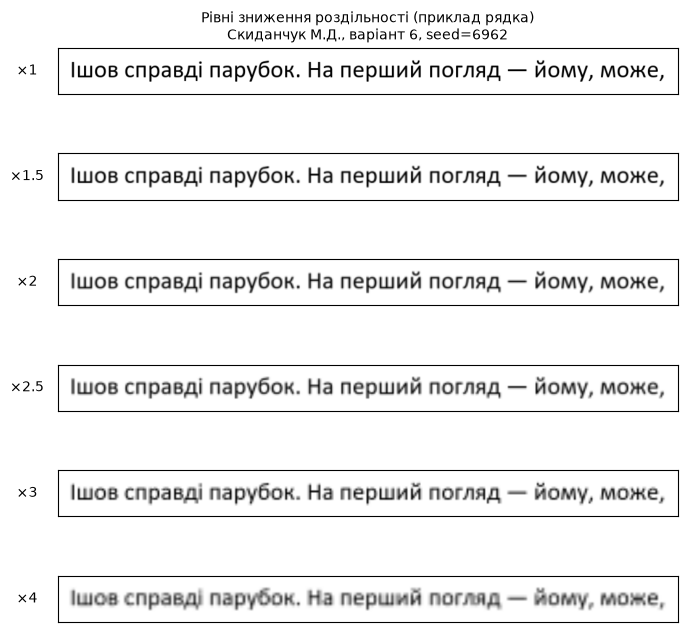

In [7]:
LEVELS = [1, 1.5, 2, 2.5, 3, 4]

def degrade(img, factor):
    """Зниження роздільності в `factor` разів із поверненням до початкового розміру."""
    if factor == 1:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, round(w / factor)), max(1, round(h / factor))),
                       interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)

# ілюстрація рівнів на одному рядку
fig, axes = plt.subplots(len(LEVELS), 1, figsize=(8, 1.2 * len(LEVELS) + 0.8))
for ax, lvl in zip(axes, LEVELS):
    ax.imshow(degrade(synth[0]["img"], lvl), cmap="gray", vmin=0, vmax=255)
    ax.set_ylabel(f"×{lvl}", rotation=0, labelpad=22, va="center")
    ax.set_xticks([]); ax.set_yticks([])
stamp(axes[0], "Рівні зниження роздільності (приклад рядка)")
fig.savefig("figures/fig0_degradation_levels.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Відкритий набір: вибір 30 карток Perestoroha

Набір містить цілі картки (сторінки), а не вирізані рядки, тому за методичкою достатньо 20 сторінок; беремо **30 карток**, випадково обраних з усіх 430 за допомогою `default_rng([SEED, 3])`. Ідентифікатори зберігаються у `data/perestoroha_ids.json`. Еталон картки — рядки поля `transcription`, з'єднані пробілом. Зображення (300 dpi, ~1160×752) переводяться у відтінки сірого.

In [8]:
from datasets import load_dataset, concatenate_datasets
from collections import Counter
import json

ds_all = load_dataset("lang-uk/perestoroha-ocr")
full = concatenate_datasets([ds_all[s] for s in ds_all])      # train + validation + test = 430 карток
N_CARDS = 30
card_idx = np.sort(np.random.default_rng([SEED, 3]).choice(len(full), size=N_CARDS, replace=False))

cards = []
for i in card_idx:
    row = full[int(i)]
    gt = " ".join(l.strip() for l in row["transcription"].splitlines() if l.strip())
    gray = cv2.cvtColor(np.array(row["image"].convert("RGB")), cv2.COLOR_RGB2GRAY)
    cards.append({"id": row["id"], "gt": gt, "img": gray})

with open("data/perestoroha_ids.json", "w", encoding="utf-8") as f:
    json.dump([c["id"] for c in cards], f, ensure_ascii=False, indent=1)
print("Карток:", len(cards), "| розмір першої:", cards[0]["img"].shape)
print("Приклад еталону:", cards[0]["gt"])

Карток: 30 | розмір першої: (748, 1158)
Приклад еталону: Таковоє мовы єго по влоску не розумѣли на то высажоныє, ледво килька их было, и то сопротивни- ковъ православію нашему. Львів, 1605-1606, Перест. 38


Символів в еталоні: 5571; поза сучасним алфавітом: 244 (4.4%)
'ы' U+044B CYRILLIC SMALL LETTER YERU 86
'ъ' U+044A CYRILLIC SMALL LETTER HARD SIGN 83
'ѣ' U+0463 CYRILLIC SMALL LETTER YAT 62
'…' U+2026 HORIZONTAL ELLIPSIS 5
'║' U+2551 BOX DRAWINGS DOUBLE VERTICAL 4
'⟨' U+27E8 MATHEMATICAL LEFT ANGLE BRACKET 1
'⟩' U+27E9 MATHEMATICAL RIGHT ANGLE BRACKET 1
'‹' U+2039 SINGLE LEFT-POINTING ANGLE QUOTATION MARK 1
'›' U+203A SINGLE RIGHT-POINTING ANGLE QUOTATION MARK 1


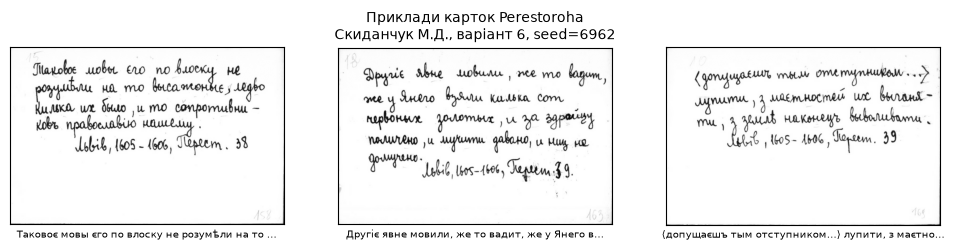

In [9]:
# Інвентар символів еталону: які символи лежать поза сучасним алфавітом
UK_ALPHABET = set("абвгґдеєжзиіїйклмнопрстуфхцчшщьюя")
counter = Counter("".join(c["gt"] for c in cards))
total_chars = sum(counter.values())
def is_modern(ch):
    return ch.lower() in UK_ALPHABET or (ch.isascii() and not ch.isalpha()) or ch == " "
outside = {ch: n for ch, n in counter.items() if not is_modern(ch) and not ch.isascii()}
OOA_SHARE = sum(outside.values()) / total_chars
print(f"Символів в еталоні: {total_chars}; поза сучасним алфавітом: {sum(outside.values())} ({OOA_SHARE:.1%})")
for ch, n in sorted(outside.items(), key=lambda kv: -kv[1])[:20]:
    print(repr(ch), f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n)

# приклади карток для звіту
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, cards[:3]):
    ax.imshow(c["img"], cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(c["gt"][:45] + "…", fontsize=7)
stamp(axes[1], "Приклади карток Perestoroha")
fig.savefig("figures/fig1_perestoroha_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Попередня обробка (абляційний набір конфігурацій)

Кроки: `upscale2` — збільшення вдвічі (бікубічна інтерполяція); `median` — медіанний фільтр 3×3; `clahe` — адаптивне вирівнювання контрасту; `otsu` — глобальна бінаризація Оцу; `adaptive` — адаптивна гаусова бінаризація. Шість конфігурацій абляційного експерименту (мінімум за методичкою — 4) перевіряють гіпотезу Г6.

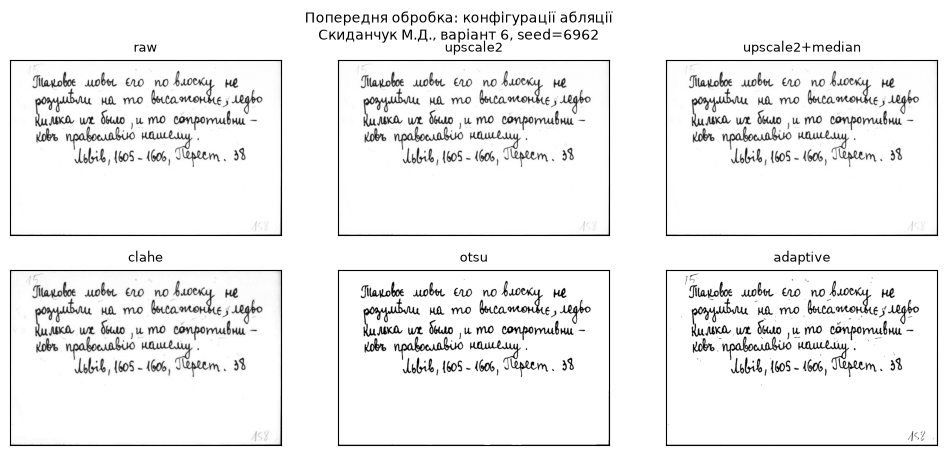

In [10]:
def preprocess(gray, steps):
    """Послідовне застосування кроків попередньої обробки до зображення у відтінках сірого."""
    out = gray
    for s in steps:
        if s == "upscale2":
            out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
        elif s == "median":
            out = cv2.medianBlur(out, 3)
        elif s == "clahe":
            out = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(out)
        elif s == "otsu":
            _, out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        elif s == "adaptive":
            out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                        cv2.THRESH_BINARY, 31, 15)
        else:
            raise ValueError(f"Невідомий крок: {s}")
    return out

ABLATION = {
    "raw": (),
    "upscale2": ("upscale2",),
    "upscale2+median": ("upscale2", "median"),
    "clahe": ("clahe",),
    "otsu": ("otsu",),
    "adaptive": ("adaptive",),
}

# ілюстрація: одна картка після кожної конфігурації
fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for ax, (name, steps) in zip(axes.ravel(), ABLATION.items()):
    ax.imshow(preprocess(cards[0]["img"], steps), cmap="gray")
    ax.set_title(name, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Попередня обробка: конфігурації абляції\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig2_preprocessing_configs.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Інструменти розпізнавання: EasyOCR і PaddleOCR

Обидва інструменти повертають області тексту з оцінкою впевненості. Для сторінкового розпізнавання фрагменти групуються в рядки за вертикальним положенням (поріг — 0,6 медіанної висоти фрагмента), всередині рядка впорядковуються зліва направо та з'єднуються пробілом. Впевненість сторінки — середнє значення за фрагментами. Час вимірюється `time.perf_counter()`.

In [11]:
os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"   # не перевіряти доступність джерел моделей
import easyocr
from paddleocr import PaddleOCR

reader = easyocr.Reader(["uk", "en"], gpu=False)

PADDLE_FAST = True   # True: легка детекція + східнослов'янське розпізнавання; False: типові моделі lang="uk"

def make_paddle():
    """PaddleOCR: oneDNN вимкнено (збій PIR/oneDNN у Paddle 3.x на CPU Windows)."""
    base = dict(enable_mkldnn=False, use_doc_orientation_classify=False,
                use_doc_unwarping=False, use_textline_orientation=False)
    candidates = []
    if PADDLE_FAST:
        candidates.append(("легка детекція + eslav-розпізнавання", dict(
            base, text_detection_model_name="PP-OCRv5_mobile_det",
            text_recognition_model_name="eslav_PP-OCRv5_mobile_rec")))
    candidates.append(('типові моделі, lang="uk"', dict(base, lang="uk")))
    for name, kw in candidates:
        try:
            ocr = PaddleOCR(**kw)
            r = next(iter(ocr.predict(cv2.cvtColor(synth[0]["img"], cv2.COLOR_GRAY2BGR))))
            c = cer(synth[0]["gt"], " ".join(r["rec_texts"]))
            print(f"PaddleOCR [{name}]: контрольний CER = {c:.3f}")
            if c < 0.3:
                return ocr
        except Exception as e:                       # noqa: BLE001
            print(f"PaddleOCR [{name}] ->", repr(e)[:300])
    raise RuntimeError("Не вдалося ініціалізувати PaddleOCR")

paddle_ocr = make_paddle()

def join_items(items):
    """items: список (cx, cy, h, text, conf) -> (текст сторінки, середня впевненість)."""
    if not items:
        return "", 0.0
    h_med = float(np.median([it[2] for it in items]))
    items = sorted(items, key=lambda it: it[1])
    rows, cur = [], [items[0]]
    for it in items[1:]:
        if abs(it[1] - np.mean([c[1] for c in cur])) < 0.6 * h_med:
            cur.append(it)
        else:
            rows.append(cur); cur = [it]
    rows.append(cur)
    text = " ".join(" ".join(t[3] for t in sorted(r, key=lambda t: t[0])) for r in rows)
    return text, float(np.mean([it[4] for it in items]))

def ocr_easyocr(img):
    t0 = time.perf_counter()
    res = reader.readtext(img)
    items = [(np.mean([p[0] for p in b]), np.mean([p[1] for p in b]),
              max(p[1] for p in b) - min(p[1] for p in b), t, float(c)) for b, t, c in res]
    text, conf = join_items(items)
    return text, conf, time.perf_counter() - t0

def ocr_paddle(img):
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    t0 = time.perf_counter()
    items = []
    for r in paddle_ocr.predict(img):
        polys = r["rec_polys"] if "rec_polys" in r else r["dt_polys"]
        for t, s, p in zip(r["rec_texts"], r["rec_scores"], polys):
            p = np.asarray(p)
            items.append((p[:, 0].mean(), p[:, 1].mean(), p[:, 1].max() - p[:, 1].min(), t, float(s)))
    text, conf = join_items(items)
    return text, conf, time.perf_counter() - t0

ENGINES = {"EasyOCR": ocr_easyocr, "PaddleOCR": ocr_paddle}

Using CPU. Note: This module is much faster with a GPU.
Creating model: ('PP-OCRv5_mobile_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\lenov\.paddlex\official_models\PP-OCRv5_mobile_det`.
Creating model: ('eslav_PP-OCRv5_mobile_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\lenov\.paddlex\official_models\eslav_PP-OCRv5_mobile_rec`.


PaddleOCR [легка детекція + eslav-розпізнавання]: контрольний CER = 0.000


In [12]:
# ---- димовий тест: по одному зображенню кожної групи ----
import paddle
print("easyocr", easyocr.__version__, "| paddleocr", __import__("paddleocr").__version__, "| paddle", paddle.__version__)

def load_own_gray(path, long_side=2000):
    gray = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
    k = long_side / max(gray.shape)
    return cv2.resize(gray, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)

with open("my_photos/page01_diffuse.txt", encoding="utf-8") as f:
    own_gt = f.read()
tests = {
    "синтетика": (synth[0]["img"], synth[0]["gt"]),
    "Perestoroha": (cards[0]["img"], cards[0]["gt"]),
    "власна сторінка": (load_own_gray("my_photos/page01_diffuse.jpg"), own_gt),
}
for gname, (img, gt) in tests.items():
    for ename, fn in ENGINES.items():
        text, conf, sec = fn(img)
        print(f"[{gname} | {ename}] CER={cer(gt, text):.3f} conf={conf:.2f} {sec:.1f} c")
        print("   еталон:", gt[:90].replace(chr(10), " "))
        print("   вихід :", text[:90])

easyocr 1.7.2 | paddleocr 3.7.0 | paddle 3.3.1
[синтетика | EasyOCR] CER=0.096 conf=0.77 0.9 c
   еталон: Ішов справді парубок. На перший погляд — йому, може,
   вихід : Ішов справді парубок. Ha перший погляд йому, може;
[синтетика | PaddleOCR] CER=0.000 conf=0.99 0.5 c
   еталон: Ішов справді парубок. На перший погляд — йому, може,
   вихід : Ішов справді парубок. На перший погляд — йому, може,
[Perestoroha | EasyOCR] CER=0.811 conf=0.32 7.6 c
   еталон: Таковоє мовы єго по влоску не розумѣли на то высажоныє, ледво килька их было, и то сопроти
   вихід : 72 Jilotol0є   Jobu Cno YO Юлоск { K pоtub KO mvo (utCo"иtoн&te uфbо Кцлко wt {wuoo W YO (
[Perestoroha | PaddleOCR] CER=0.318 conf=0.69 2.1 c
   еталон: Таковоє мовы єго по влоску не розумѣли на то высажоныє, ледво килька их было, и то сопроти
   вихід : Таково мови сло по воску не розуии на то висатонеедо Килка их бо,и то сопротиви- Кoвъ прав
[власна сторінка | EasyOCR] CER=0.862 conf=0.37 28.2 c
   еталон: Парубок плівся повагом, п

## 8. Повні експерименти

Усі прогони записують результат у `data/results.csv` (один рядок = один запуск інструмента) і **можуть бути перервані та продовжені**: уже виконані запуски пропускаються. Групи даних запускаються окремими клітинками: власні фото → синтетика → абляція → картки Perestoroha. Перед вимірюванням часу кожен інструмент прогрівається одним запуском. Метрики: `cer`, `wer` (базова нормалізація), `cer_hist`, `wer_hist` (з нормалізацією історичних графем), `len_ratio` (довжина виходу / довжина еталону, контроль вставленого або пропущеного тексту). Для власних фото рукопису, написаного великими літерами, порівняння виконується без урахування регістру (`fold=True`).

In [13]:
import json
from tqdm.auto import tqdm
from PIL import ImageOps

RESULTS_CSV = "data/results.csv"

def _key(group, item, level, engine, prep):
    return (str(group), str(item), f"{float(level):g}", str(engine), str(prep))

def load_done():
    if not os.path.exists(RESULTS_CSV):
        return set()
    d = pd.read_csv(RESULTS_CSV, usecols=["group", "item", "level", "engine", "prep"])
    return {_key(*r) for r in d.itertuples(index=False, name=None)}

def run_tasks(tasks):
    """Виконує запуски, яких ще немає в results.csv, і дописує результати рядок за рядком."""
    done = load_done()
    todo = [t for t in tasks if _key(t["group"], t["item"], t["level"], t["engine"], t["prep"]) not in done]
    print(f"Усього запусків: {len(tasks)}; уже виконано: {len(tasks) - len(todo)}; залишилось: {len(todo)}")
    for t in tqdm(todo):
        try:
            text, conf, sec = ENGINES[t["engine"]](t["img_fn"]())
        except Exception as e:                           # noqa: BLE001
            print("ПОМИЛКА:", t["group"], t["item"], t["engine"], repr(e)[:150])
            text, conf, sec = "", 0.0, float("nan")
        gt, fold = t["gt"], t.get("fold", False)
        row = {"group": t["group"], "item": t["item"], "level": t["level"], "engine": t["engine"],
               "prep": t["prep"], "fold": fold,
               "cer": cer(gt, text, fold=fold), "wer": wer(gt, text, fold=fold),
               "cer_hist": cer(gt, text, hist=True, fold=fold), "wer_hist": wer(gt, text, hist=True, fold=fold),
               "len_ratio": len(normalize(text)) / max(len(normalize(gt)), 1),
               "conf": conf, "sec": sec, "gt": gt, "pred": text}
        pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV),
                                   index=False, encoding="utf-8")

# прогрів моделей (перший запуск довший за наступні)
for _fn in ENGINES.values():
    _fn(synth[0]["img"])
print("Прогрів виконано")

Прогрів виконано


### 8.1 Власні фотографії

Три фото рукописної сторінки (розсіяне світло, бічне світло з тінню, кут ≈40°) і фрагмент старого друкованого напису («Фішка», 2005; область обрізання береться з `plaque01.crop.json`). Фото читаються з урахуванням орієнтації EXIF; довша сторона сторінок зводиться до 2000 пікселів, фрагмент напису не масштабується.

In [14]:
def load_own(path, long_side=2000, box=None):
    im = ImageOps.exif_transpose(Image.open(path)).convert("L")
    if box is not None:
        im = im.crop(tuple(box))
    gray = np.array(im)
    if long_side:
        k = long_side / max(gray.shape)
        gray = cv2.resize(gray, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)
    return gray

def read_txt(path):
    with open(path, encoding="utf-8") as f:
        return f.read()

with open("my_photos/plaque01.crop.json", encoding="utf-8") as f:
    PLAQUE_BOX = json.load(f)["box"]

OWN = [  # (ім'я, файл, область обрізання, масштабувати)
    ("page01_diffuse", "my_photos/page01_diffuse.jpg", None, 2000),
    ("page02_side", "my_photos/page02_side.jpg", None, 2000),
    ("page03_angle", "my_photos/page03_angle.jpg", None, 2000),
    ("plaque01", "my_photos/plaque01.jpg", PLAQUE_BOX, None),
]
own_tasks = []
for name, path, box, ls in OWN:
    gt = read_txt(path[:-4] + ".txt")
    for eng in ENGINES:
        own_tasks.append({"group": "own", "item": name, "level": 1, "engine": eng, "prep": "raw",
                          "gt": gt, "fold": True,
                          "img_fn": lambda p=path, b=box, l=ls: load_own(p, l, b)})
run_tasks(own_tasks)

Усього запусків: 8; уже виконано: 8; залишилось: 0


0it [00:00, ?it/s]


### 8.2 Синтетичні рядки: крива стійкості (40 рядків × 6 рівнів × 2 інструменти)

In [15]:
synth_tasks = [
    {"group": "synthetic", "item": s["id"], "level": lvl, "engine": eng, "prep": "raw", "gt": s["gt"],
     "img_fn": lambda s=s, lvl=lvl: degrade(s["img"], lvl)}
    for s in synth for lvl in LEVELS for eng in ENGINES
]
run_tasks(synth_tasks)

Усього запусків: 480; уже виконано: 480; залишилось: 0


0it [00:00, ?it/s]


### 8.3 Абляційний експеримент (перші 10 карток, без зниження роздільності, 6 конфігурацій)

In [16]:
ABL_N = 10
abl_tasks = [
    {"group": "ablation", "item": c["id"], "level": 1, "engine": eng, "prep": name, "gt": c["gt"],
     "img_fn": lambda c=c, steps=steps: preprocess(c["img"], steps)}
    for c in cards[:ABL_N] for name, steps in ABLATION.items() for eng in ENGINES
]
run_tasks(abl_tasks)

Усього запусків: 120; уже виконано: 120; залишилось: 0


0it [00:00, ?it/s]


### 8.4 Картки Perestoroha: крива стійкості (30 карток × 6 рівнів × 2 інструменти)

Це найдовший прогін (орієнтовно 1–1,5 год на CPU). Його можна перервати (Stop) і запустити клітинку знову: виконані запуски не повторюватимуться.

In [17]:
open_tasks = [
    {"group": "perestoroha", "item": c["id"], "level": lvl, "engine": eng, "prep": "raw", "gt": c["gt"],
     "img_fn": lambda c=c, lvl=lvl: degrade(c["img"], lvl)}
    for c in cards for lvl in LEVELS for eng in ENGINES
]
run_tasks(open_tasks)

Усього запусків: 360; уже виконано: 360; залишилось: 0


0it [00:00, ?it/s]


### 8.5 Зведення результатів

Зведені таблиці, з яких беруться числа звіту: **A** — CER, WER, час і впевненість за групами даних (×1, без обробки); **B** — CER / WER за рівнями зниження роздільності; **C** — початок еталона й розпізнаного тексту власних зображень. Результати абляції — у розділі 9.4.

In [18]:
from IPython.display import display, HTML

def show(df):
    """Показує таблицю без індексу (для скріншота у звіт)."""
    display(HTML(df.to_html(index=False, escape=True, justify="left")))

res = pd.read_csv(RESULTS_CSV)
res["level"] = res["level"].astype(float)
raw = res[res.prep == "raw"]
print(res.groupby(["group", "engine"]).agg(запусків=("cer", "size"), CER=("cer", "mean"),
                                           WER=("wer", "mean"), час_с=("sec", "mean")).round(3))

# ---- Таблиця A: результати за групами даних (без зниження роздільності, без обробки) ----
own = raw[raw.group == "own"]
GROUPS = [("Синтетика ×1 (40)", raw[(raw.group == "synthetic") & (raw.level == 1)]),
          ("Perestoroha ×1 (30)", raw[(raw.group == "perestoroha") & (raw.level == 1)]),
          ("Власна сторінка: розсіяне світло (1)", own[own["item"] == "page01_diffuse"]),
          ("Власна сторінка: бічне світло (1)", own[own["item"] == "page02_side"]),
          ("Власна сторінка: кут ≈ 40° (1)", own[own["item"] == "page03_angle"]),
          ("Друкований напис (1)", own[own["item"] == "plaque01"])]
rows = []
for name, d in GROUPS:
    for eng in ["EasyOCR", "PaddleOCR"]:
        x = d[d.engine == eng]
        rows.append({"Група даних (n)": name, "Інструмент": eng, "CER": x.cer.mean(), "WER": x.wer.mean(),
                     "Час, с": x.sec.mean(), "Впевненість": x.conf.mean()})
print("\nТаблиця A. Результати за групами даних (×1, без обробки):")
show(pd.DataFrame(rows).round({"CER": 3, "WER": 3, "Час, с": 2, "Впевненість": 2}))

# ---- Таблиця B: CER / WER за рівнями зниження роздільності ----
rows = []
for lv in [1, 1.5, 2, 2.5, 3, 4]:
    row = {"Рівень": f"×{lv:g}"}
    for g, gname in [("synthetic", "Синтетика"), ("perestoroha", "Perestoroha")]:
        for eng in ["EasyOCR", "PaddleOCR"]:
            d = raw[(raw.group == g) & (raw.engine == eng) & np.isclose(raw.level, lv)]
            row[f"{gname}: {eng} CER / WER"] = f"{d.cer.mean():.3f} / {d.wer.mean():.3f}"
    rows.append(row)
print("\nТаблиця B. CER і WER за рівнями зниження роздільності:")
show(pd.DataFrame(rows))

# ---- Таблиця C: початок еталона і розпізнаного тексту власних зображень ----
def _clip(s, n):
    s = " ".join(str(s).split())
    return s if len(s) <= n else s[:n].rstrip() + " …"
rows = []
for it, name in [("page01_diffuse", "Сторінка, розсіяне світло"), ("page02_side", "Сторінка, бічне світло"),
                 ("page03_angle", "Сторінка, кут ≈ 40°"), ("plaque01", "Друкований напис")]:
    n = 300 if it == "plaque01" else 110
    x = own[own["item"] == it]
    rows.append({"Зображення": name, "Джерело": "Еталон", "Текст (початок)": _clip(x.iloc[0]["gt"], n), "CER": ""})
    for eng in ["EasyOCR", "PaddleOCR"]:
        r_ = x[x.engine == eng].iloc[0]
        rows.append({"Зображення": "", "Джерело": eng, "Текст (початок)": _clip(r_["pred"], n), "CER": f"{r_['cer']:.3f}"})
print("\nТаблиця C. Фрагменти розпізнаного тексту власних зображень:")
show(pd.DataFrame(rows))

                         запусків    CER    WER   час_с
group         engine                                   
ablation      EasyOCR          60  0.803  1.223  13.094
              PaddleOCR        60  0.611  0.925   3.451
own           EasyOCR           4  0.560  1.430  25.754
              PaddleOCR         4  0.572  0.799   5.839
perestoroha   EasyOCR         180  0.798  1.235   7.104
              PaddleOCR       180  0.573  0.921   2.711
synthetic     EasyOCR         240  0.152  0.410   2.007
              PaddleOCR       240  0.013  0.059   0.798
synthetic_big EasyOCR         160  0.420  0.871   1.043
              PaddleOCR       160  0.042  0.173   0.614

Таблиця A. Результати за групами даних (×1, без обробки):


Група даних (n),Інструмент,CER,WER,"Час, с",Впевненість
Синтетика ×1 (40),EasyOCR,0.065,0.237,1.97,0.81
Синтетика ×1 (40),PaddleOCR,0.009,0.040,0.74,0.97
Perestoroha ×1 (30),EasyOCR,0.799,1.177,7.06,0.38
Perestoroha ×1 (30),PaddleOCR,0.570,0.908,2.21,0.64
Власна сторінка: розсіяне світло (1),EasyOCR,0.651,1.636,44.42,0.37
Власна сторінка: розсіяне світло (1),PaddleOCR,0.534,0.874,9.39,0.57
Власна сторінка: бічне світло (1),EasyOCR,0.554,1.298,35.92,0.43
Власна сторінка: бічне світло (1),PaddleOCR,0.668,0.874,7.04,0.60
Власна сторінка: кут ≈ 40° (1),EasyOCR,0.946,2.318,17.91,0.39
Власна сторінка: кут ≈ 40° (1),PaddleOCR,0.973,1.000,2.31,0.62



Таблиця B. CER і WER за рівнями зниження роздільності:


Рівень,Синтетика: EasyOCR CER / WER,Синтетика: PaddleOCR CER / WER,Perestoroha: EasyOCR CER / WER,Perestoroha: PaddleOCR CER / WER
×1,0.065 / 0.237,0.009 / 0.040,0.799 / 1.177,0.570 / 0.908
×1.5,0.055 / 0.211,0.010 / 0.041,0.799 / 1.221,0.560 / 0.912
×2,0.065 / 0.257,0.006 / 0.027,0.803 / 1.239,0.559 / 0.909
×2.5,0.092 / 0.353,0.008 / 0.041,0.795 / 1.239,0.548 / 0.915
×3,0.167 / 0.514,0.011 / 0.044,0.796 / 1.258,0.576 / 0.935
×4,0.469 / 0.889,0.037 / 0.161,0.800 / 1.273,0.623 / 0.948



Таблиця C. Фрагменти розпізнаного тексту власних зображень:


Зображення,Джерело,Текст (початок),CER
"Сторінка, розсіяне світло",Еталон,"Парубок плівся повагом, позакладавши руки назад себе; позирав навкруги своїми блискучими очима; іноді зупинявс …",
,EasyOCR,"[ІАрw50к ПЛіВСЯ ПОВАГОМ ((osALJ КВШМ Q'KИ Kl%А; СЕfE (ОЗИРА6 НА""крчГи (₽oі МИ ЕЛИСКЧИИМ И 0Ч1f4; iкЮЯ' 3ЧПИ Н9 …",0.651
,PaddleOCR,CEBE; ПОЗИРAВ НАBКРУГИ СВОЙМИ И БЛИСКУЧИИ ОЧИМА; ИНОРИ 34иНявсЯ і AоBГо РО3ГАв PE-HE5YA6 HA АРАНИЙ МИСТОЧОК BE …,0.534
"Сторінка, бічне світло",Еталон,"Парубок плівся повагом, позакладавши руки назад себе; позирав навкруги своїми блискучими очима; іноді зупинявс …",
,EasyOCR,Пхгчє? < ПЛіВс? ГОРАГМ ПООЗАLЛА ₽АВДИ Рк# k?Ад СЕБЕ fА6 ґхйгчГи CвойRи ЕлиСкЧииММ MKfA; ікод'' 3ЧПИ НЯ6С% 1 до …,0.554
,PaddleOCR,"AE-HE6YA6 H4 АРАНИЙ МИСТОЧОК BECHOHI KAJHMI-aM ЗАЦВИДИ,ПОЗЕЗЕНИЛИ: КУМКАЮТЬ В НИХ АБИ РАНО И ВЕЧР. ОГ ОПИНИВСЬ …",0.668
"Сторінка, кут ≈ 40°",Еталон,"Парубок плівся повагом, позакладавши руки назад себе; позирав навкруги своїми блискучими очима; іноді зупинявс …",
,EasyOCR,"t1 ПАр""ееу M4 ""A, C ₽f ( 0 1o 'g 4fA ₽ '3{ $ % Af' SF VЕVЕ кxrчfи €eo ""и стлv < FoRАtoм (tegAA JA ,,Ав/и 7Ю,"", …",0.946
,PaddleOCR,"103UPAB POSTSAC9AB ) СкиAAн4ук M.Д. П3-46,0B-1-26",0.973
Друкований напис,Еталон,"ОДІССЕЯ ГЕРМЕСА 190229695 Ти - давньогрецький бог Гермес, але твоє безтурбот- не життя на Олімпі під загрозою. Ти загубив корону Зевса, і її частини тепер розкидані по всьому світу. Те- пер доведеться спуститися в грішний світ і забрати уламки корони, використовуючи меч, спис і хитрість у боротьбі з …",


## 9. Графіки метрик і їх інтерпретація

Усі графіки будуються з `data/results.csv` і мають персональний підпис (`stamp`). Довірчі інтервали — бутстреп (B = 2000) із `default_rng([SEED, …])` за зразками; для порівняння інструментів на тих самих зразках використовується бутстреп **парної** різниці. На кривих і діаграмах CER — середнє за зразками (макроусереднення).

In [19]:
RES = pd.read_csv(RESULTS_CSV)
RES["level"] = RES["level"].astype(float)
ENG = [e for e in ["EasyOCR", "PaddleOCR"] if e in RES.engine.unique()]
COL = {"EasyOCR": "#2a6fbb", "PaddleOCR": "#d4572a"}
B = 2000

def boot_ci(x, seed=0, B=B):
    """Середнє та 95% бутстреп-інтервал."""
    x = np.asarray(x, float)
    r = np.random.default_rng([SEED, 9, int(seed)])
    m = x[r.integers(0, len(x), (B, len(x)))].mean(axis=1)
    return x.mean(), *np.percentile(m, [2.5, 97.5])

def boot_diff(a, b, seed=0, B=B):
    """Середня різниця a-b (парна) та 95% бутстреп-інтервал."""
    d = np.asarray(a, float) - np.asarray(b, float)
    r = np.random.default_rng([SEED, 10, int(seed)])
    m = d[r.integers(0, len(d), (B, len(d)))].mean(axis=1)
    return d.mean(), *np.percentile(m, [2.5, 97.5])

def sel(group, eng=None, level=None, prep="raw", col="cer"):
    d = RES[(RES.group == group) & (RES.prep == prep)]
    if eng is not None:
        d = d[d.engine == eng]
    if level is not None:
        d = d[np.isclose(d.level, level)]
    return d.sort_values("item")

print(RES.groupby(["group", "engine"]).size())

group          engine   
ablation       EasyOCR       60
               PaddleOCR     60
own            EasyOCR        4
               PaddleOCR      4
perestoroha    EasyOCR      180
               PaddleOCR    180
synthetic      EasyOCR      240
               PaddleOCR    240
synthetic_big  EasyOCR      160
               PaddleOCR    160
dtype: int64


### 9.1 Крива стійкості: CER від рівня зниження роздільності (з бутстреп-смугами)

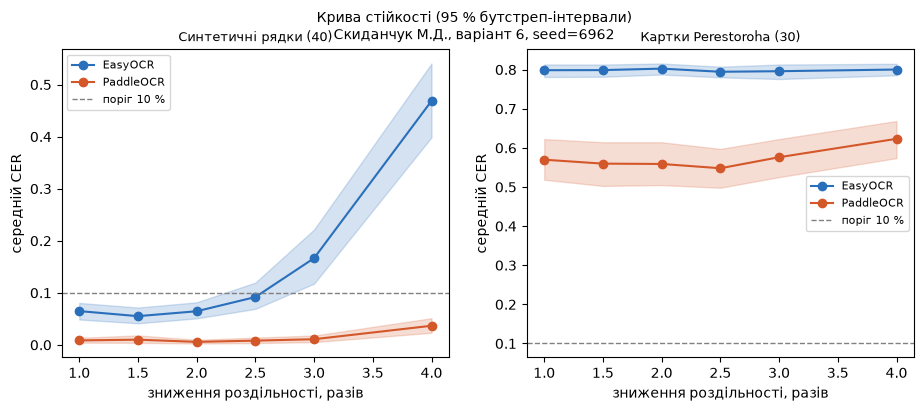


synthetic: середній CER [95 % інтервал]
engine               EasyOCR             PaddleOCR
level                                             
1.0     0.065 [0.049; 0.081]  0.009 [0.004; 0.014]
1.5     0.055 [0.041; 0.072]  0.010 [0.004; 0.018]
2.0     0.065 [0.051; 0.082]  0.006 [0.003; 0.010]
2.5     0.092 [0.069; 0.120]  0.008 [0.003; 0.014]
3.0     0.167 [0.118; 0.222]  0.011 [0.005; 0.018]
4.0     0.469 [0.399; 0.541]  0.037 [0.023; 0.051]

perestoroha: середній CER [95 % інтервал]
engine               EasyOCR             PaddleOCR
level                                             
1.0     0.799 [0.781; 0.813]  0.570 [0.519; 0.623]
1.5     0.799 [0.782; 0.813]  0.560 [0.503; 0.614]
2.0     0.803 [0.788; 0.816]  0.559 [0.505; 0.614]
2.5     0.795 [0.780; 0.808]  0.548 [0.498; 0.597]
3.0     0.796 [0.776; 0.813]  0.576 [0.525; 0.622]
4.0     0.800 [0.785; 0.815]  0.623 [0.574; 0.669]


In [20]:
def curve_table(group):
    rows = []
    for eng in ENG:
        for lvl in LEVELS:
            v = sel(group, eng, lvl).cer.values
            m, lo, hi = boot_ci(v, seed=int(lvl * 10))
            rows.append({"engine": eng, "level": lvl, "mean": m, "lo": lo, "hi": hi, "n": len(v)})
    return pd.DataFrame(rows)

CURVES = {g: curve_table(g) for g in ["synthetic", "perestoroha"]}
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (g, title) in zip(axes, [("synthetic", "Синтетичні рядки (40)"), ("perestoroha", "Картки Perestoroha (30)")]):
    for eng in ENG:
        t = CURVES[g][CURVES[g].engine == eng]
        ax.plot(t.level, t["mean"], marker="o", color=COL[eng], label=eng)
        ax.fill_between(t.level, t.lo, t.hi, color=COL[eng], alpha=0.2)
    ax.axhline(0.10, ls="--", c="gray", lw=1, label="поріг 10 %")
    ax.set_xlabel("зниження роздільності, разів"); ax.set_ylabel("середній CER"); ax.set_title(title, fontsize=9)
    ax.legend(fontsize=8)
fig.suptitle(f"Крива стійкості (95 % бутстреп-інтервали)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig3_robustness_curves.png", dpi=150, bbox_inches="tight")
plt.show()
for g in CURVES:
    print(f"\n{g}: середній CER [95 % інтервал]")
    print(CURVES[g].assign(ci=lambda t: t.apply(lambda r: f"{r['mean']:.3f} [{r.lo:.3f}; {r.hi:.3f}]", axis=1))
          .pivot(index="level", columns="engine", values="ci"))

### 9.2 Діаграма розмаху й гістограми CER

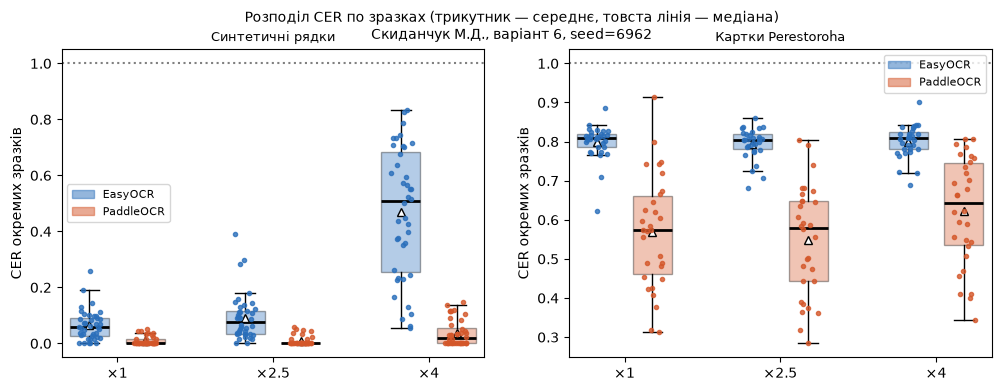

Частка повних провалів (CER ≥ 1) та медіана/середнє:
synthetic    EasyOCR    ×1: медіана=0.058 середнє=0.065 CER≥1: 0%
synthetic    EasyOCR    ×4: медіана=0.508 середнє=0.469 CER≥1: 0%
synthetic    PaddleOCR  ×1: медіана=0.000 середнє=0.009 CER≥1: 0%
synthetic    PaddleOCR  ×4: медіана=0.019 середнє=0.037 CER≥1: 0%
perestoroha  EasyOCR    ×1: медіана=0.809 середнє=0.799 CER≥1: 0%
perestoroha  EasyOCR    ×4: медіана=0.808 середнє=0.800 CER≥1: 0%
perestoroha  PaddleOCR  ×1: медіана=0.574 середнє=0.570 CER≥1: 0%
perestoroha  PaddleOCR  ×4: медіана=0.643 середнє=0.623 CER≥1: 0%


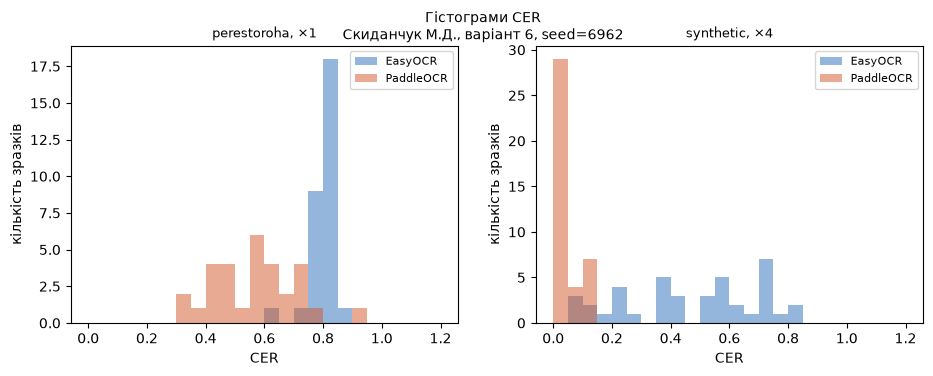

In [21]:
def boxplot_group(ax, group, levels):
    pos, data, cols, ticks = [], [], [], []
    p = 1.0
    for lvl in levels:
        for eng in ENG:
            v = sel(group, eng, lvl).cer.values
            data.append(v); pos.append(p); cols.append(COL[eng]); p += 1
        ticks.append((p - 1 - (len(ENG) - 1) / 2, f"×{lvl:g}")); p += 0.8
    bp = ax.boxplot(data, positions=pos, widths=0.7, showmeans=True, patch_artist=True,
                    meanprops=dict(marker="^", markerfacecolor="white", markeredgecolor="k"),
                    medianprops=dict(color="k", lw=2), flierprops=dict(marker=""))
    r = np.random.default_rng([SEED, 11])
    for patch, c, x, v in zip(bp["boxes"], cols, pos, data):
        patch.set_facecolor(c); patch.set_alpha(0.35)
        ax.scatter(x + r.uniform(-0.2, 0.2, len(v)), v, s=9, color=c, alpha=0.8, zorder=3)
    ax.set_xticks([t[0] for t in ticks]); ax.set_xticklabels([t[1] for t in ticks])
    ax.axhline(1.0, ls=":", c="gray"); ax.set_ylabel("CER окремих зразків")
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=COL[e], alpha=0.5) for e in ENG], ENG, fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
boxplot_group(axes[0], "synthetic", [1, 2.5, 4]); axes[0].set_title("Синтетичні рядки", fontsize=9)
boxplot_group(axes[1], "perestoroha", [1, 2.5, 4]); axes[1].set_title("Картки Perestoroha", fontsize=9)
fig.suptitle(f"Розподіл CER по зразках (трикутник — середнє, товста лінія — медіана)\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig4_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

print("Частка повних провалів (CER ≥ 1) та медіана/середнє:")
for g in ["synthetic", "perestoroha"]:
    for eng in ENG:
        for lvl in [1, 4]:
            v = sel(g, eng, lvl).cer.values
            print(f"{g:12s} {eng:10s} ×{lvl:g}: медіана={np.median(v):.3f} середнє={v.mean():.3f} CER≥1: {np.mean(v >= 1):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (g, lvl) in zip(axes, [("perestoroha", 1), ("synthetic", 4)]):
    for eng in ENG:
        ax.hist(sel(g, eng, lvl).cer.values, bins=np.linspace(0, 1.2, 25), alpha=0.5, color=COL[eng], label=eng)
    ax.set_xlabel("CER"); ax.set_ylabel("кількість зразків"); ax.set_title(f"{g}, ×{lvl}", fontsize=9); ax.legend(fontsize=8)
fig.suptitle(f"Гістограми CER\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig5_histograms.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.3 Впевненість і CER; крива ризик-покриття

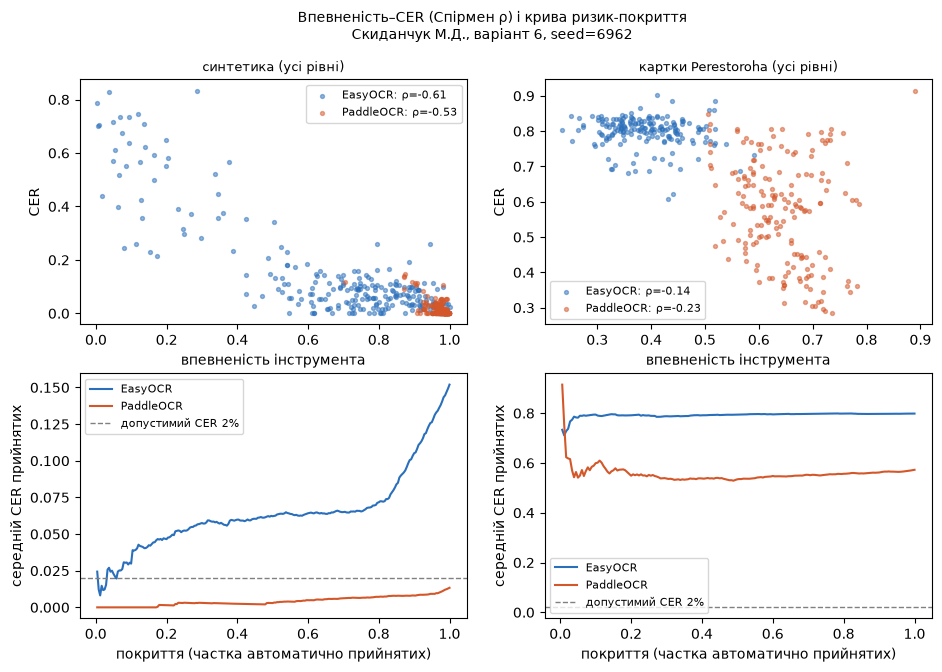

synthetic    EasyOCR    ρ=-0.61  покриття при CER≤2%: 6%  поріг впевненості: 0.97
synthetic    PaddleOCR  ρ=-0.53  покриття при CER≤2%: 100%  поріг впевненості: 0.70
perestoroha  EasyOCR    ρ=-0.14  покриття при CER≤2%: 0%  поріг впевненості: —
perestoroha  PaddleOCR  ρ=-0.23  покриття при CER≤2%: 0%  поріг впевненості: —


In [22]:
def risk_coverage(d):
    d = d.sort_values("conf", ascending=False)
    cum = d.cer.expanding().mean().values
    cov = np.arange(1, len(d) + 1) / len(d)
    return d.conf.values, cum, cov

TARGET = 0.02
RC_RESULT = {}
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, (g, title) in enumerate([("synthetic", "синтетика (усі рівні)"), ("perestoroha", "картки Perestoroha (усі рівні)")]):
    d_all = RES[(RES.group == g) & (RES.prep == "raw")]
    for eng in ENG:
        d = d_all[d_all.engine == eng]
        rho, pval = spearmanr(d.conf, d.cer)
        axes[0, j].scatter(d.conf, d.cer, s=8, alpha=0.5, color=COL[eng], label=f"{eng}: ρ={rho:.2f}")
        conf_s, cum, cov = risk_coverage(d)
        axes[1, j].plot(cov, cum, color=COL[eng], label=eng)
        ok = np.where(cum <= TARGET)[0]
        RC_RESULT[(g, eng)] = {"rho": rho, "coverage": (cov[ok[-1]] if len(ok) else 0.0),
                               "threshold": (conf_s[ok[-1]] if len(ok) else None)}
    axes[0, j].set_xlabel("впевненість інструмента"); axes[0, j].set_ylabel("CER"); axes[0, j].set_title(title, fontsize=9)
    axes[0, j].legend(fontsize=8)
    axes[1, j].axhline(TARGET, ls="--", c="gray", lw=1, label=f"допустимий CER {TARGET:.0%}")
    axes[1, j].set_xlabel("покриття (частка автоматично прийнятих)"); axes[1, j].set_ylabel("середній CER прийнятих")
    axes[1, j].legend(fontsize=8)
fig.suptitle(f"Впевненість–CER (Спірмен ρ) і крива ризик-покриття\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig6_confidence_risk_coverage.png", dpi=150, bbox_inches="tight")
plt.show()
for k, v in RC_RESULT.items():
    th = "—" if v["threshold"] is None else f"{v['threshold']:.2f}"
    print(f"{k[0]:12s} {k[1]:10s} ρ={v['rho']:+.2f}  покриття при CER≤{TARGET:.0%}: {v['coverage']:.0%}  поріг впевненості: {th}")

### 9.4 Абляція попередньої обробки та діаграма «час–CER» (фронт Парето)

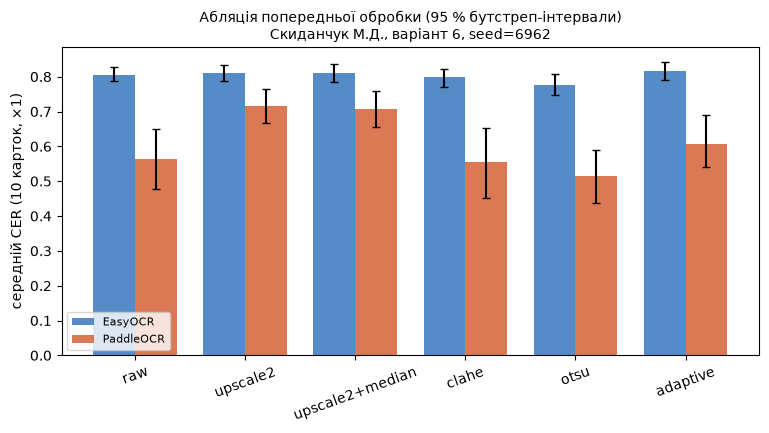

   engine            prep   cer    lo    hi  delta_vs_raw   d_lo   d_hi    sec
  EasyOCR             raw 0.805 0.789 0.827         0.000  0.000  0.000  6.994
  EasyOCR        upscale2 0.811 0.787 0.833         0.006 -0.014  0.025 25.427
  EasyOCR upscale2+median 0.812 0.785 0.837         0.007 -0.010  0.025 25.447
  EasyOCR           clahe 0.798 0.770 0.823        -0.007 -0.026  0.013  7.031
  EasyOCR            otsu 0.777 0.746 0.809        -0.027 -0.055  0.001  6.842
  EasyOCR        adaptive 0.816 0.792 0.842         0.011 -0.007  0.029  6.821
PaddleOCR             raw 0.563 0.476 0.649         0.000  0.000  0.000  2.000
PaddleOCR        upscale2 0.717 0.668 0.765         0.153  0.085  0.230  6.657
PaddleOCR upscale2+median 0.708 0.657 0.758         0.145  0.085  0.211  6.365
PaddleOCR           clahe 0.556 0.453 0.652        -0.007 -0.049  0.037  1.943
PaddleOCR            otsu 0.515 0.438 0.588        -0.049 -0.102 -0.001  1.693
PaddleOCR        adaptive 0.608 0.539 0.689         

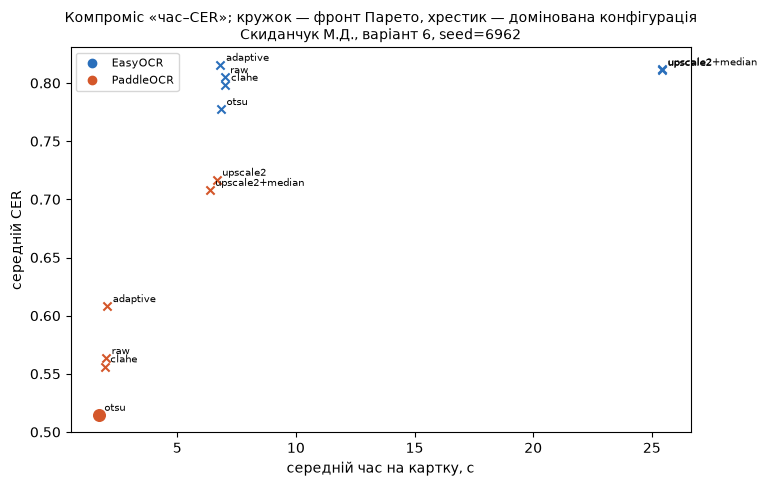

Домінуються: ['EasyOCR/raw', 'EasyOCR/upscale2', 'EasyOCR/upscale2+median', 'EasyOCR/clahe', 'EasyOCR/otsu', 'EasyOCR/adaptive', 'PaddleOCR/raw', 'PaddleOCR/upscale2', 'PaddleOCR/upscale2+median', 'PaddleOCR/clahe', 'PaddleOCR/adaptive']


In [23]:
ABL = RES[RES.group == "ablation"]
abl_rows = []
for eng in ENG:
    base = ABL[(ABL.engine == eng) & (ABL.prep == "raw")].sort_values("item")
    for prep in ABLATION:
        d = ABL[(ABL.engine == eng) & (ABL.prep == prep)].sort_values("item")
        m, lo, hi = boot_ci(d.cer.values, seed=list(ABLATION).index(prep))
        dm, dlo, dhi = boot_diff(d.cer.values, base.cer.values, seed=list(ABLATION).index(prep))
        abl_rows.append({"engine": eng, "prep": prep, "cer": m, "lo": lo, "hi": hi,
                         "delta_vs_raw": dm, "d_lo": dlo, "d_hi": dhi, "sec": d.sec.mean()})
ABL_TBL = pd.DataFrame(abl_rows)

fig, ax = plt.subplots(figsize=(9, 4))
w = 0.38
for k, eng in enumerate(ENG):
    t = ABL_TBL[ABL_TBL.engine == eng].set_index("prep").loc[list(ABLATION)]
    x = np.arange(len(t)) + (k - 0.5) * w
    ax.bar(x, t.cer, w, color=COL[eng], alpha=0.8, label=eng,
           yerr=[t.cer - t.lo, t.hi - t.cer], capsize=3)
ax.set_xticks(np.arange(len(ABLATION))); ax.set_xticklabels(list(ABLATION), rotation=20)
ax.set_ylabel("середній CER (10 карток, ×1)"); ax.legend(fontsize=8)
stamp(ax, "Абляція попередньої обробки (95 % бутстреп-інтервали)")
fig.savefig("figures/fig7_ablation.png", dpi=150, bbox_inches="tight")
plt.show()
print(ABL_TBL.round(3).to_string(index=False))

def pareto_front(points):
    """points: список (час, CER); повертає індекси недомінованих (менше — краще за обома осями)."""
    idx = []
    for i, (t, c) in enumerate(points):
        if not any((t2 <= t and c2 <= c) and (t2 < t or c2 < c) for j, (t2, c2) in enumerate(points) if j != i):
            idx.append(i)
    return idx

fig, ax = plt.subplots(figsize=(8, 5))
pts = list(zip(ABL_TBL.sec, ABL_TBL.cer))
front = set(pareto_front(pts))
for i, r in ABL_TBL.iterrows():
    ax.scatter(r.sec, r.cer, s=70 if i in front else 35, color=COL[r.engine],
               marker="o" if i in front else "x", zorder=3)
    ax.annotate(r.prep, (r.sec, r.cer), fontsize=7, xytext=(4, 3), textcoords="offset points")
fr = sorted(front, key=lambda i: ABL_TBL.sec[i])
ax.step([ABL_TBL.sec[i] for i in fr], [ABL_TBL.cer[i] for i in fr], where="post", c="gray", lw=1)
ax.set_xlabel("середній час на картку, с"); ax.set_ylabel("середній CER")
ax.legend([plt.Line2D([], [], color=COL[e], marker="o", ls="") for e in ENG], ENG, fontsize=8)
stamp(ax, "Компроміс «час–CER»; кружок — фронт Парето, хрестик — домінована конфігурація")
fig.savefig("figures/fig8_time_cer_pareto.png", dpi=150, bbox_inches="tight")
plt.show()
print("Домінуються:", [f"{ABL_TBL.engine[i]}/{ABL_TBL.prep[i]}" for i in range(len(ABL_TBL)) if i not in front])

### 9.5 Систематичні помилки: діаграма замін символів

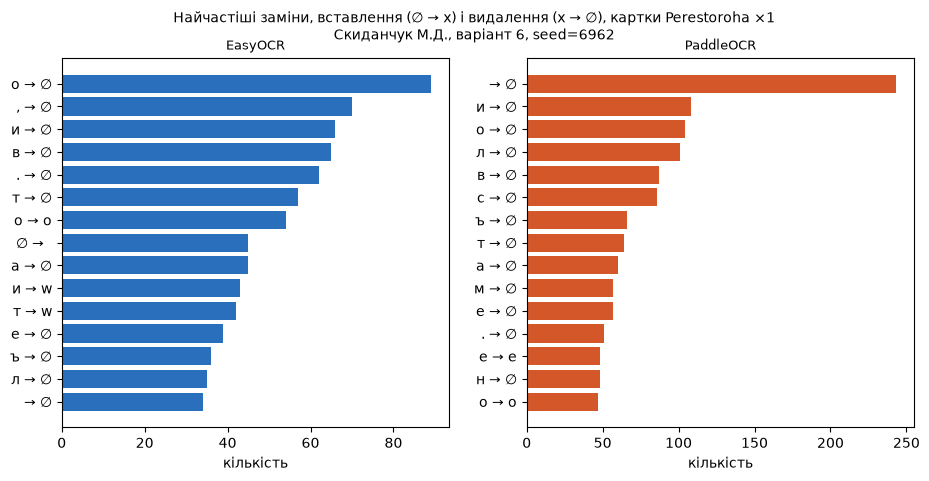

EasyOCR: частка виходів із латинськими літерами: 64%
PaddleOCR: частка виходів із латинськими літерами: 46%


In [24]:
def confusion_counts(df):
    c = Counter()
    for gt, pred in zip(df["gt"], df["pred"].fillna("")):
        c.update(edit_ops(gt, str(pred)))
    return c

def op_label(op):
    kind, a, b = op
    return {"replace": f"{a} → {b}", "delete": f"{a} → ∅", "insert": f"∅ → {b}"}[kind]

fig, axes = plt.subplots(1, len(ENG), figsize=(5.5 * len(ENG), 4.8))
axes = np.atleast_1d(axes)
CONF = {}
for ax, eng in zip(axes, ENG):
    cnt = confusion_counts(sel("perestoroha", eng, 1))
    CONF[eng] = cnt
    top = cnt.most_common(15)
    ax.barh([op_label(o) for o, _ in top][::-1], [n for _, n in top][::-1], color=COL[eng])
    ax.set_xlabel("кількість"); ax.set_title(eng, fontsize=9)
fig.suptitle(f"Найчастіші заміни, вставлення (∅ → x) і видалення (x → ∅), картки Perestoroha ×1\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig9_confusions.png", dpi=150, bbox_inches="tight")
plt.show()

# окремо: гомогліфи (латиниця всередині кириличного слова) у виході
LAT = re.compile(r"[A-Za-z]")
for eng in ENG:
    d = RES[(RES.engine == eng) & (RES.group.isin(["synthetic", "perestoroha", "own"])) & (RES.prep == "raw")]
    share = d.pred.fillna("").map(lambda s: bool(LAT.search(str(s)))).mean()
    print(f"{eng}: частка виходів із латинськими літерами: {share:.0%}")

### 9.6 Порівняння CER на синтетичних, відкритих і власних даних

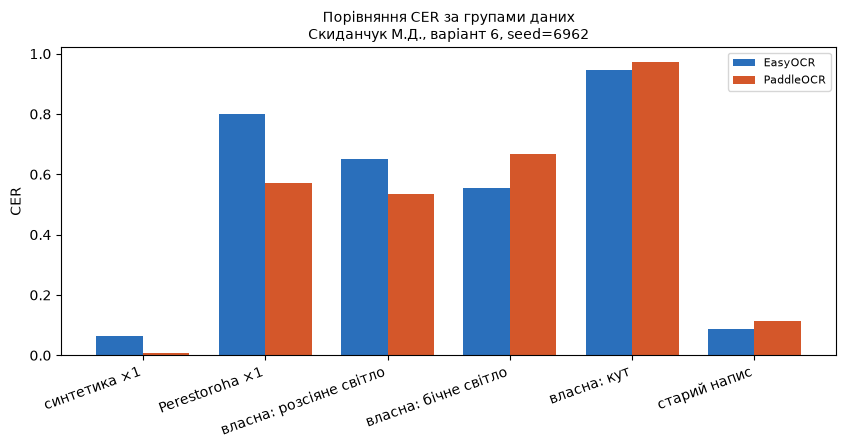

engine                   EasyOCR  PaddleOCR
група                                      
синтетика ×1               0.065      0.009
Perestoroha ×1             0.799      0.570
власна: розсіяне світло    0.651      0.534
власна: бічне світло       0.554      0.668
власна: кут                0.946      0.973
старий напис               0.087      0.113
EasyOCR: власні сторінки / синтетика ×1 = 11.1; Perestoroha ×1 / синтетика ×1 = 12.3
PaddleOCR: власні сторінки / синтетика ×1 = 84.7; Perestoroha ×1 / синтетика ×1 = 66.6


In [25]:
groups = [("синтетика ×1", sel("synthetic", level=1)), ("Perestoroha ×1", sel("perestoroha", level=1)),
          ("власна: розсіяне світло", RES[(RES.group == "own") & (RES.item == "page01_diffuse")]),
          ("власна: бічне світло", RES[(RES.group == "own") & (RES.item == "page02_side")]),
          ("власна: кут", RES[(RES.group == "own") & (RES.item == "page03_angle")]),
          ("старий напис", RES[(RES.group == "own") & (RES.item == "plaque01")])]
cmp_rows = []
for name, d in groups:
    for eng in ENG:
        v = d[d.engine == eng].cer.values
        cmp_rows.append({"група": name, "engine": eng, "cer": v.mean(), "n": len(v)})
CMP = pd.DataFrame(cmp_rows)
fig, ax = plt.subplots(figsize=(10, 4))
for k, eng in enumerate(ENG):
    t = CMP[CMP.engine == eng]
    ax.bar(np.arange(len(t)) + (k - 0.5) * 0.38, t.cer, 0.38, color=COL[eng], label=eng)
ax.set_xticks(np.arange(len(groups))); ax.set_xticklabels([g[0] for g in groups], rotation=20, ha="right")
ax.set_ylabel("CER"); ax.legend(fontsize=8)
stamp(ax, "Порівняння CER за групами даних")
fig.savefig("figures/fig10_groups_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print(CMP.pivot(index="група", columns="engine", values="cer").round(3).loc[[g[0] for g in groups]])
for eng in ENG:
    t = CMP[CMP.engine == eng].set_index("група").cer
    print(f"{eng}: власні сторінки / синтетика ×1 = {t[['власна: розсіяне світло','власна: бічне світло','власна: кут']].mean() / max(t['синтетика ×1'], 1e-9):.1f}; "
          f"Perestoroha ×1 / синтетика ×1 = {t['Perestoroha ×1'] / max(t['синтетика ×1'], 1e-9):.1f}")

### 9.7 Особливість варіанта: вплив нормалізації історичних графем на CER

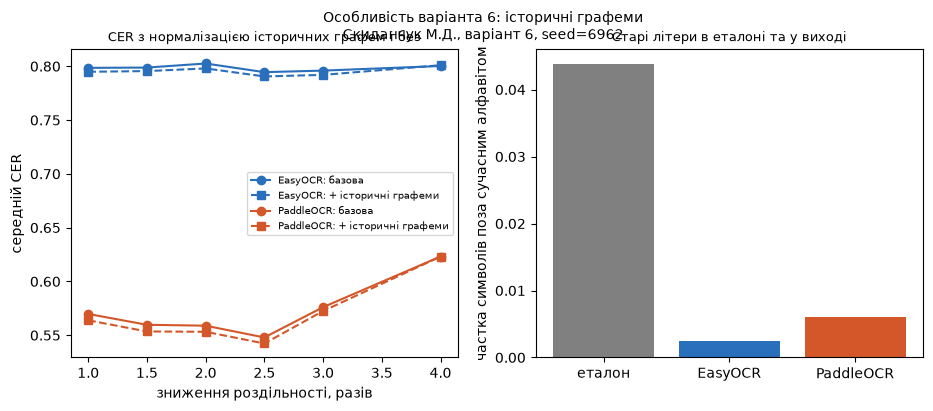

   engine  CER базова ×1  CER hist ×1  різниця       інтервал
  EasyOCR          0.799        0.795    0.004 [0.001; 0.007]
PaddleOCR          0.570        0.564    0.006 [0.004; 0.008]
Частка символів еталону поза сучасним алфавітом: 4.4%


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
HIST_ROWS = []
for eng in ENG:
    base = [sel("perestoroha", eng, l).cer.values.mean() for l in LEVELS]
    hist = [sel("perestoroha", eng, l).cer_hist.values.mean() for l in LEVELS]
    axes[0].plot(LEVELS, base, "-o", color=COL[eng], label=f"{eng}: базова")
    axes[0].plot(LEVELS, hist, "--s", color=COL[eng], label=f"{eng}: + історичні графеми")
    a, b = sel("perestoroha", eng, 1).cer.values, sel("perestoroha", eng, 1).cer_hist.values
    dm, lo, hi = boot_diff(a, b, seed=77)
    HIST_ROWS.append({"engine": eng, "CER базова ×1": a.mean(), "CER hist ×1": b.mean(),
                      "різниця": dm, "інтервал": f"[{lo:.3f}; {hi:.3f}]"})
axes[0].set_xlabel("зниження роздільності, разів"); axes[0].set_ylabel("середній CER"); axes[0].legend(fontsize=7)
axes[0].set_title("CER з нормалізацією історичних графем і без", fontsize=9)
# частка символів еталону поза сучасним алфавітом і частка таких символів у виході
share_pred = {eng: np.mean([sum(not is_modern(ch) and not ch.isascii() for ch in str(p)) / max(len(str(p)), 1)
                            for p in sel("perestoroha", eng, 1).pred.fillna("")]) for eng in ENG}
axes[1].bar(["еталон"] + ENG, [OOA_SHARE] + [share_pred[e] for e in ENG],
            color=["gray"] + [COL[e] for e in ENG])
axes[1].set_ylabel("частка символів поза сучасним алфавітом"); axes[1].set_title("Старі літери в еталоні та у виході", fontsize=9)
fig.suptitle(f"Особливість варіанта 6: історичні графеми\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig11_historical_graphemes.png", dpi=150, bbox_inches="tight")
plt.show()
print(pd.DataFrame(HIST_ROWS).round(3).to_string(index=False))
print(f"Частка символів еталону поза сучасним алфавітом: {OOA_SHARE:.1%}")

### 9.8 П'ять найгірших зразків (Perestoroha ×1, без обробки)

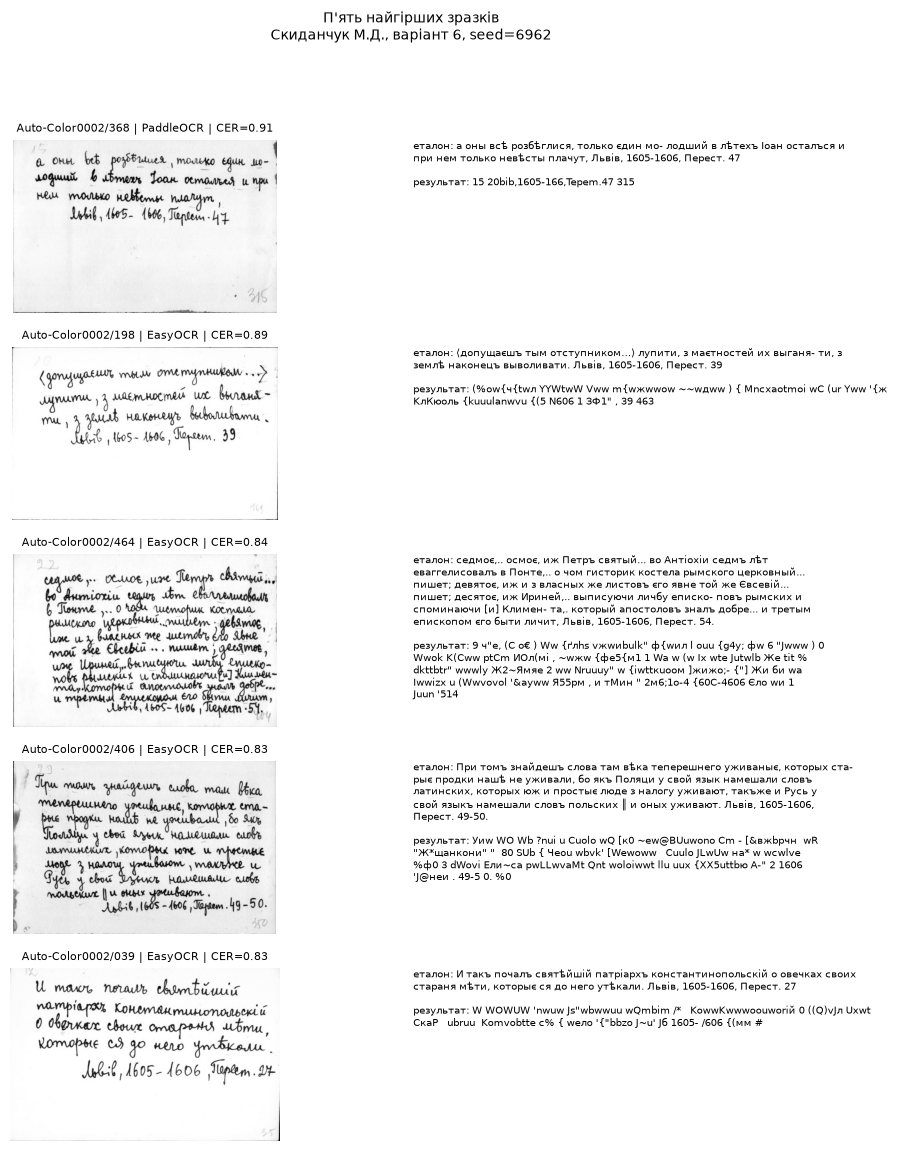

              item    engine   cer  cer_hist  len_ratio  conf
Auto-Color0002/368 PaddleOCR 0.915     0.913      0.233 0.889
Auto-Color0002/198   EasyOCR 0.885     0.875      0.918 0.439
Auto-Color0002/464   EasyOCR 0.842     0.841      0.732 0.352
Auto-Color0002/406   EasyOCR 0.833     0.832      0.737 0.302
Auto-Color0002/039   EasyOCR 0.829     0.832      0.929 0.382


In [27]:
import textwrap
card_by_id = {c["id"]: c["img"] for c in cards}
worst = sel("perestoroha", level=1).nlargest(5, "cer")
fig, axes = plt.subplots(5, 2, figsize=(12, 13), gridspec_kw={"width_ratios": [1, 1.3]})
for r, (_, row) in zip(axes, worst.iterrows()):
    r[0].imshow(card_by_id[row["item"]], cmap="gray"); r[0].axis("off")
    r[0].set_title(f"{row['item']} | {row['engine']} | CER={row['cer']:.2f}", fontsize=8)
    r[1].axis("off")
    r[1].text(0, 1, "еталон: " + textwrap.fill(row["gt"], 70) + "\n\nрезультат: " + textwrap.fill(str(row["pred"]), 70),
              va="top", fontsize=7)
fig.suptitle(f"П'ять найгірших зразків\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.savefig("figures/fig12_worst5.png", dpi=150, bbox_inches="tight")
plt.show()
print(worst[["item", "engine", "cer", "cer_hist", "len_ratio", "conf"]].round(3).to_string(index=False))

### 9.9 Старі літери (ы, ъ, ѣ…): що інструменти роблять із історичними графемами

Вирівнювання результату з еталоном (без розширеної нормалізації) показує долю кожної старої літери з еталону: *збережена точно*, *замінена на сучасний відповідник* (за таблицею `HIST_MAP`; для «ъ» відповідником вважається пропуск) або *інша помилка*.

Історичні літери в еталоні (картки Perestoroha ×1):
                      EasyOCR  PaddleOCR
збережена точно             0         19
сучасний відповідник       37         76
інша помилка              194        136
                      EasyOCR  PaddleOCR
збережена точно          0.00       0.08
сучасний відповідник     0.16       0.33
інша помилка             0.84       0.59

За літерами (рядок = літера, стовпці = доля в кожній категорії):
EasyOCR
   збережена точно  сучасний відповідник  інша помилка
ъ                0                    36            47
ы                0                     1            85
ѣ                0                     0            62
PaddleOCR
   збережена точно  сучасний відповідник  інша помилка
ъ                5                    66            12
ы               14                    10            62
ѣ                0                     0            62


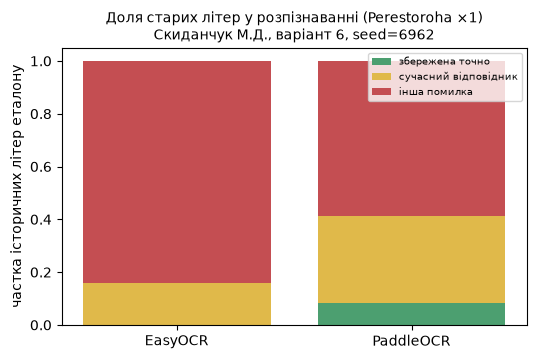

In [28]:
HIST_CHARS = set(HIST_MAP)
def hist_fate(eng):
    st, per = Counter(), Counter()
    d = sel("perestoroha", eng, 1)
    for gt, pred in zip(d["gt"], d["pred"].fillna("")):
        g_, p_ = normalize(gt), normalize(str(pred))
        for tag, i1, i2, j1, j2 in Levenshtein.opcodes(g_, p_):
            for k, i in enumerate(range(i1, i2)):
                ch = g_[i]
                if ch not in HIST_CHARS:
                    continue
                if tag == "equal":
                    fate = "збережена точно"
                elif tag == "replace" and p_[j1 + k] == HIST_MAP[ch]:
                    fate = "сучасний відповідник"
                elif tag == "delete" and HIST_MAP[ch] == "":
                    fate = "сучасний відповідник"
                else:
                    fate = "інша помилка"
                st[fate] += 1; per[(ch, fate)] += 1
    return st, per

FATES = ["збережена точно", "сучасний відповідник", "інша помилка"]
HF = {eng: hist_fate(eng) for eng in ENG}
tbl = pd.DataFrame({eng: {f: HF[eng][0][f] for f in FATES} for eng in ENG})
print("Історичні літери в еталоні (картки Perestoroha ×1):")
print(tbl)
print((tbl / tbl.sum()).round(2))
print("\nЗа літерами (рядок = літера, стовпці = доля в кожній категорії):")
for eng in ENG:
    per = HF[eng][1]
    rows = {ch: [per[(ch, f)] for f in FATES] for ch in sorted({c for c, _ in per})}
    print(eng); print(pd.DataFrame(rows, index=FATES).T)

fig, ax = plt.subplots(figsize=(6, 3.6))
bottom = np.zeros(len(ENG))
for f, c in zip(FATES, ["#4c9f70", "#e0b94a", "#c44e52"]):
    vals = np.array([tbl.loc[f, e] / tbl[e].sum() for e in ENG])
    ax.bar(ENG, vals, bottom=bottom, color=c, label=f); bottom += vals
ax.set_ylabel("частка історичних літер еталону"); ax.legend(fontsize=7)
stamp(ax, "Доля старих літер у розпізнаванні (Perestoroha ×1)")
fig.savefig("figures/fig13_historical_fate.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.10 Правила постобробки та їх ефект на CER

Три правила, що відповідають спостереженим помилкам: **R1** — латинські літери-гомогліфи всередині слів, що містять кирилицю, замінюються кириличними; **R2** — видалення «сміттєвих» символів (`# % { } | ~ € ₽ …`), яких немає в еталонах; **R3** — `;` перед словом із малої літери замінюється на `,` (EasyOCR на синтетиці плутає кому з крапкою з комою). Ефект вимірюється зміною CER на тих самих зразках (парний бутстреп).

In [29]:
LAT2CYR = str.maketrans({"o": "о", "O": "О", "e": "е", "E": "Е", "a": "а", "A": "А", "c": "с", "C": "С",
                         "p": "р", "P": "Р", "x": "х", "X": "Х", "y": "у", "T": "Т", "H": "Н", "K": "К",
                         "M": "М", "B": "В", "i": "і", "I": "І"})
CYR = re.compile(r"[а-яґєіїА-ЯҐЄІЇ]")
GARBAGE = re.compile(r"[#%{}|~`€₽<>@&*_^\[\]]")

def rule_homoglyph(t):
    return " ".join(w.translate(LAT2CYR) if CYR.search(w) else w for w in t.split(" "))
def rule_garbage(t):
    return re.sub(r"\s+", " ", GARBAGE.sub("", t))
def rule_semicolon(t):
    return re.sub(r";(?=\s+[а-яґєіїa-z])", ",", t)

RULES = {"R1 гомогліфи": rule_homoglyph, "R2 сміття": rule_garbage, "R3 ; → ,": rule_semicolon}
rule_rows = []
for grp, lvl in [("synthetic", 1), ("perestoroha", 1)]:
    for eng in ENG:
        d = sel(grp, eng, lvl)
        before = d["cer"].values
        for name, fn in RULES.items():
            after = np.array([cer(g_, fn(str(p_)), fold=f_) for g_, p_, f_ in zip(d["gt"], d["pred"].fillna(""), d["fold"])])
            dm, lo, hi = boot_diff(after, before, seed=5)
            rule_rows.append({"група": f"{grp} ×{lvl}", "engine": eng, "правило": name,
                              "CER до": before.mean(), "CER після": after.mean(), "Δ": dm, "95 % інтервал Δ": f"[{lo:.4f}; {hi:.4f}]"})
RULES_TBL = pd.DataFrame(rule_rows)
print(RULES_TBL.round(4).to_string(index=False))

         група    engine      правило  CER до  CER після       Δ    95 % інтервал Δ
  synthetic ×1   EasyOCR R1 гомогліфи  0.0649     0.0645 -0.0004  [-0.0012; 0.0000]
  synthetic ×1   EasyOCR    R2 сміття  0.0649     0.0649  0.0000   [0.0000; 0.0000]
  synthetic ×1   EasyOCR     R3 ; → ,  0.0649     0.0613 -0.0036 [-0.0077; -0.0000]
  synthetic ×1 PaddleOCR R1 гомогліфи  0.0086     0.0086  0.0000   [0.0000; 0.0000]
  synthetic ×1 PaddleOCR    R2 сміття  0.0086     0.0086  0.0000   [0.0000; 0.0000]
  synthetic ×1 PaddleOCR     R3 ; → ,  0.0086     0.0106  0.0021   [0.0004; 0.0043]
perestoroha ×1   EasyOCR R1 гомогліфи  0.7985     0.7870 -0.0115 [-0.0161; -0.0075]
perestoroha ×1   EasyOCR    R2 сміття  0.7985     0.7867 -0.0118 [-0.0161; -0.0079]
perestoroha ×1   EasyOCR     R3 ; → ,  0.7985     0.7986  0.0001  [-0.0004; 0.0005]
perestoroha ×1 PaddleOCR R1 гомогліфи  0.5698     0.5572 -0.0126 [-0.0198; -0.0064]
perestoroha ×1 PaddleOCR    R2 сміття  0.5698     0.5698  0.0000   [0.0000; 

### 9.11 Перевірка питання 2: чи вдвічі звузить інтервал збільшення вибірки в 4 рази?

Найширший інтервал на синтетичній кривій стійкості — на рівні ×4 (EasyOCR). Оцінка за правилом 1/√n: щоб звузити інтервал удвічі, потрібно **в 4 рази більше зразків**. Перевірка: на рівні ×4 розпізнається 160 зображень (рядки з корпусу вибираються з поверненням за `default_rng([SEED, 5])`, шрифт і розмір — за `default_rng([SEED, 6])`), порівнюється ширина 95 % бутстреп-інтервалу при n = 40 та n = 160. Це лише 320 запусків (кілька хвилин).

In [30]:
BIG_N = 160
rng_big_idx = np.random.default_rng([SEED, 5])
rng_big_font = np.random.default_rng([SEED, 6])
big = []
for k, i in enumerate(rng_big_idx.choice(len(corpus), size=BIG_N, replace=True)):
    fp = FONTS[int(rng_big_font.integers(len(FONTS)))]
    size = int(rng_big_font.integers(28, 45))
    big.append({"id": f"big_{k:03d}", "gt": corpus[int(i)], "img": render_line(corpus[int(i)], fp, size)})

big_tasks = [{"group": "synthetic_big", "item": b["id"], "level": 4, "engine": eng, "prep": "raw", "gt": b["gt"],
              "img_fn": lambda b=b: degrade(b["img"], 4)} for b in big for eng in ENGINES]
run_tasks(big_tasks)

RES = pd.read_csv(RESULTS_CSV); RES["level"] = RES["level"].astype(float)
Q2_ROWS = []
for eng in ENG:
    v40 = RES[(RES.group == "synthetic") & (RES.engine == eng) & np.isclose(RES.level, 4)]["cer"].values
    v160 = RES[(RES.group == "synthetic_big") & (RES.engine == eng)]["cer"].values
    m1, lo1, hi1 = boot_ci(v40, seed=401); m2, lo2, hi2 = boot_ci(v160, seed=402)
    Q2_ROWS.append({"engine": eng, "n": 40, "CER": m1, "ширина інтервалу": hi1 - lo1,
                    "n (повт.)": len(v160), "CER (повт.)": m2, "ширина (повт.)": hi2 - lo2,
                    "звуження, разів": (hi1 - lo1) / (hi2 - lo2)})
print(pd.DataFrame(Q2_ROWS).round(4).to_string(index=False))

Усього запусків: 320; уже виконано: 320; залишилось: 0


0it [00:00, ?it/s]

   engine  n    CER  ширина інтервалу  n (повт.)  CER (повт.)  ширина (повт.)  звуження, разів
  EasyOCR 40 0.4686            0.1460        160       0.4202          0.0702           2.0798
PaddleOCR 40 0.0367            0.0284        160       0.0424          0.0222           1.2789


### 9.12 Результати для власних зображень у JSON з метаданими

In [31]:
import hashlib
from PIL import ExifTags

def exif_info(path):
    ex = Image.open(path).getexif()
    tags = {ExifTags.TAGS.get(k, k): v for k, v in ex.items()}
    clean = lambda v: v.replace("\x00", "").strip() if isinstance(v, str) else v   # EXIF-рядки можуть містити нульові байти
    return clean(tags.get("DateTime")), clean(tags.get("Model"))

CONF_THRESHOLD = 0.80   # нижче — запис позначається needs_review
VERSIONS = {"EasyOCR": easyocr.__version__, "PaddleOCR": __import__("paddleocr").__version__}
PARAMS = {"EasyOCR": {"langs": ["uk", "en"], "gpu": False},
          "PaddleOCR": {"lang": "uk", "fast_models": PADDLE_FAST, "mkldnn": False}}
own_paths = {n: (p, ls) for n, p, _, ls in OWN}
own_json = []
for _, r in RES[RES.group == "own"].sort_values(["item", "engine"]).iterrows():
    path, ls = own_paths[r["item"]]
    taken, camera = exif_info(path)
    code9 = re.search(r"\b\d{9}\b", str(r["pred"])) if r["item"] == "plaque01" else None
    own_json.append({
        "image": os.path.basename(path), "image_sha256": hashlib.sha256(open(path, "rb").read()).hexdigest(),
        "exif": {"datetime": taken, "camera": camera},
        "engine": r["engine"], "engine_version": VERSIONS[r["engine"]], "params": PARAMS[r["engine"]],
        "preprocessing": "raw" + (f", long side {ls} px" if ls else ", crop by plaque01.crop.json"),
        "text": r["pred"], "confidence": round(float(r["conf"]), 3), "seconds": round(float(r["sec"]), 2),
        "cer": round(float(r["cer"]), 3),
        "fields": ({"catalogue_code": code9.group(0) if code9 else None,
                    "valid_length": bool(code9)} if r["item"] == "plaque01" else None),
        "needs_review": bool(r["conf"] < CONF_THRESHOLD or (r["item"] == "plaque01" and not code9)),
    })
os.makedirs("results", exist_ok=True)
with open("results/own_results.json", "w", encoding="utf-8") as f:
    json.dump(own_json, f, ensure_ascii=False, indent=2)
print(json.dumps([x for x in own_json if x["image"] == "plaque01.jpg"][0], ensure_ascii=False, indent=2))
print("Записів needs_review:", sum(x["needs_review"] for x in own_json), "з", len(own_json))

{
  "image": "plaque01.jpg",
  "image_sha256": "fe94511cec2d463e29b4763e1687f87ac82218ed27063ab0986901e8ce4bd450",
  "exif": {
    "datetime": "2026:11:08 21:36:30",
    "camera": "SM-A325F"
  },
  "engine": "EasyOCR",
  "engine_version": "1.7.2",
  "params": {
    "langs": [
      "uk",
      "en"
    ],
    "gpu": false
  },
  "preprocessing": "raw, crop by plaque01.crop.json",
  "text": "ОДІССЕЯ ГЕРМЕСА 190229695 Ти давньогрецький бог Гермес, але твоє безтурбот- не житТя на Олімпі під загрозою Ти загубив корону Зевса, i ri частини тепер розкидані по всьому світу . Те - пер доведеться с;ститися В грішний свіT ?брати уламки корони , ьу ко, истовуючи меч , сгис хитрість у бороть бі 3 ворогами",
  "confidence": 0.845,
  "seconds": 4.77,
  "cer": 0.087,
  "fields": {
    "catalogue_code": "190229695",
    "valid_length": true
  },
  "needs_review": false
}
Записів needs_review: 6 з 8


### 9.13 Числа для відповідей на питання підрозділу 7.3

In [32]:
def first_above(tbl, eng, thr=0.10):
    t = tbl[tbl.engine == eng].sort_values("level")
    hit = t[t["mean"] > thr]
    return None if hit.empty else float(hit.level.iloc[0])

print("Q1. Перший рівень, де середній CER > 10 %:")
for g_ in ["synthetic", "perestoroha"]:
    print(" ", g_, {e: first_above(CURVES[g_], e) for e in ENG})
    diff = (CURVES[g_][CURVES[g_].engine == ENG[0]].set_index("level")["mean"]
            - CURVES[g_][CURVES[g_].engine == ENG[-1]].set_index("level")["mean"])
    print("   різниця EasyOCR − PaddleOCR за рівнями:", diff.round(3).to_dict(), "| перетин кривих:", bool((diff > 0).any() and (diff < 0).any()))

print("\nQ2. Ширина 95 % інтервалу (hi − lo): плато (×1) і найгірша точка:")
for g_ in ["synthetic", "perestoroha"]:
    for e in ENG:
        t = CURVES[g_][CURVES[g_].engine == e].set_index("level")
        w = (t.hi - t.lo)
        print(f"  {g_:12s} {e:10s} ×1: {w[1.0]:.3f}; найширший: ×{w.idxmax():g} = {w.max():.3f}; n = {int(t.n.iloc[0])}")

print("\nQ3. Парна різниця EasyOCR − PaddleOCR на рівні найбільшого розриву:")
for g_ in ["synthetic", "perestoroha"]:
    best = max(LEVELS, key=lambda l: CURVES[g_][(CURVES[g_].engine == ENG[0]) & np.isclose(CURVES[g_].level, l)]["mean"].iloc[0]
               - CURVES[g_][(CURVES[g_].engine == ENG[-1]) & np.isclose(CURVES[g_].level, l)]["mean"].iloc[0])
    a, b = sel(g_, ENG[0], best).cer.values, sel(g_, ENG[-1], best).cer.values
    m, lo, hi = boot_diff(a, b, seed=int(best * 10))
    print(f"  {g_}: ×{best:g}: Δ = {m:.3f} [{lo:.3f}; {hi:.3f}] | містить нуль: {lo <= 0 <= hi}")

print("\nQ5. Спірмен і покриття при CER ≤ 2 %:")
for k, v in RC_RESULT.items():
    thr = "—" if v["threshold"] is None else f"{v['threshold']:.2f}"
    print(f"  {k}: ρ = {v['rho']:+.2f}; покриття = {v['coverage']:.0%}; поріг впевненості = {thr}")

print("\nQ6. Конфігурації та час для 10 000 карток (послідовно, 1 процес):")
ABL_TBL["годин на 10 000"] = ABL_TBL.sec * 10000 / 3600
print(ABL_TBL[["engine", "prep", "cer", "sec", "годин на 10 000"]].round(3).to_string(index=False))

print("\nQ8. П'ять найчастіших помилок (картки Perestoroha ×1):")
for eng in ENG:
    print(" ", eng, [(op_label(o), n) for o, n in CONF[eng].most_common(5)])
print("  без видалень:", {eng: [(op_label(o), n) for o, n in CONF[eng].most_common() if o[0] != "delete"][:5] for eng in ENG})

print("\nQ9. CER власних фото проти синтетики та Perestoroha:")
print(CMP.pivot(index="група", columns="engine", values="cer").round(3))

Q1. Перший рівень, де середній CER > 10 %:
  synthetic {'EasyOCR': 3.0, 'PaddleOCR': None}
   різниця EasyOCR − PaddleOCR за рівнями: {1.0: 0.056, 1.5: 0.045, 2.0: 0.059, 2.5: 0.084, 3.0: 0.156, 4.0: 0.432} | перетин кривих: False
  perestoroha {'EasyOCR': 1.0, 'PaddleOCR': 1.0}
   різниця EasyOCR − PaddleOCR за рівнями: {1.0: 0.229, 1.5: 0.239, 2.0: 0.244, 2.5: 0.247, 3.0: 0.22, 4.0: 0.177} | перетин кривих: False

Q2. Ширина 95 % інтервалу (hi − lo): плато (×1) і найгірша точка:
  synthetic    EasyOCR    ×1: 0.032; найширший: ×4 = 0.142; n = 40
  synthetic    PaddleOCR  ×1: 0.009; найширший: ×4 = 0.028; n = 40
  perestoroha  EasyOCR    ×1: 0.032; найширший: ×3 = 0.037; n = 30
  perestoroha  PaddleOCR  ×1: 0.104; найширший: ×1.5 = 0.112; n = 30

Q3. Парна різниця EasyOCR − PaddleOCR на рівні найбільшого розриву:
  synthetic: ×4: Δ = 0.432 [0.365; 0.497] | містить нуль: False
  perestoroha: ×2.5: Δ = 0.247 [0.200; 0.297] | містить нуль: False

Q5. Спірмен і покриття при CER ≤ 2 %:
  ('

## 10. Інтерпретація результатів

Усі числа нижче взято з виведення клітинок розділу 9 цього ноутбука (рівні — коефіцієнт зниження роздільності, CER — середнє по зразках, у квадратних дужках — 95 % бутстреп-інтервал, B = 2000, SEED = 6962). Порядок інтерпретації кожного графіка: осі → орієнтир → тенденція → аномалії → надійність → практичне рішення → додатковий експеримент.

### 10.1 Інтерпретація графіків

**Рис. fig3 (крива стійкості, 9.1).** *Осі:* x — зниження роздільності (×1…×4), y — середній CER; точка — середнє по 40 синтетичних рядках (ліво) або 30 карток (право). *Орієнтир:* пунктир 10 %. *Тенденція:* на синтетиці EasyOCR тримається на плато 0,055–0,065 до ×2, на ×2,5 має 0,092 [0,069; 0,120] (ще нижче порогу, але інтервал його вже перетинає), на ×3 стрибає до 0,167 [0,118; 0,222], на ×4 — до 0,469 [0,399; 0,541]; PaddleOCR майже не реагує: 0,009 на ×1 і 0,037 [0,023; 0,051] на ×4. На картках Perestoroha криві практично пласкі: EasyOCR 0,795–0,803, PaddleOCR 0,548–0,576 і лише на ×4 0,623 [0,574; 0,669]. *Аномалії:* крива PaddleOCR на картках має мінімум на ×2,5 (0,548), а не на ×1 — різниця 0,022 менша за ширину інтервалів, тож це шум, а не ефект. Причина пласких кривих на картках: помилку створює рукопис, а не роздільність (картка ×1 має ≈1160×750 пікселів, ×4 — ≈290×188). *Надійність:* на синтетиці n = 40, найширша смуга EasyOCR на ×4 — 0,142; на картках n = 30, але смуги вужчі для EasyOCR (0,032) через однорідно високий CER. *Рішення:* для друкованого тексту розпізнавати при роздільності не гірше ×2 для EasyOCR (до ×4 — для PaddleOCR); для рукописних карток зниження роздільності не є вузьким місцем — потрібна інша модель. *Додатково:* перевірити ×5…×8, щоб знайти злам PaddleOCR, і порівняти з оцінкою висоти символу в пікселях (гіпотеза: злам настає, коли висота малої літери стає меншою за ~8 пікселів).

**Рис. fig4, fig5 (діаграми розмаху та гістограми, 9.2).** *Осі:* y — CER одного зразка. *Орієнтир:* CER = 1 (повний провал). *Тенденція:* на синтетиці ×1 медіана/середнє EasyOCR 0,058/0,065, PaddleOCR 0/0,009; на ×4 — 0,508/0,469 і 0,019/0,037. На картках ×1: 0,809/0,799 і 0,574/0,570. *Аномалії:* медіана PaddleOCR на синтетиці ×1 дорівнює нулю, а середнє — 0,009: розподіл скошений праворуч, кілька рядків із помилками тягнуть середнє вгору. У EasyOCR на ×4 медіана (0,508) більша за середнє (0,469): розподіл скошений ліворуч — частина рядків ще читається добре, решта розвалюється. Повних провалів (CER ≥ 1) немає в жодній групі (0 %). *Надійність:* лише 30–40 зразків, тому форма хвоста визначена грубо. *Рішення:* для PaddleOCR на синтетиці звітувати медіану разом із середнім. *Додатково:* перевірити, чи «хвіст» пов'язаний зі шрифтом, групуючи CER за шрифтом і розміром.

**Рис. fig6 (впевненість–CER і ризик–покриття, 9.3).** *Осі:* верхні панелі — впевненість інструмента та CER зразка; нижні — частка автоматично прийнятих зразків (відсортованих за впевненістю) і середній CER прийнятих. *Орієнтир:* допустимий CER 2 %. *Тенденція:* на синтетиці ρ Спірмена = −0,61 (EasyOCR) і −0,53 (PaddleOCR): впевненість інформативна. На картках ρ = −0,14 і −0,23: впевненість майже не відрізняє добрі розпізнавання від поганих. *Аномалії:* PaddleOCR на картці Auto-Color0002/368 має впевненість 0,889 при CER 0,915 — упевнений провал (відкрито в 10.3). *Надійність:* на картках жодна точка не досягає 2 %, тож порогу не існує. *Рішення:* на синтетиці PaddleOCR можна приймати автоматично все (покриття 100 %, поріг 0,70), для EasyOCR поріг 0,97 дає лише 6 % покриття; на рукописних картках автоматичне прийняття за впевненістю неможливе, усе — на ручну перевірку. *Додатково:* відкалібрувати впевненість на окремій вибірці (ізотонічна регресія) і перевірити, чи зросте ρ.

**Рис. fig7, fig8 (абляція та діаграма «час–CER», 9.4).** *Осі:* fig7 — CER за конфігураціями для 10 карток; fig8 — час на зображення (x) і CER (y). *Орієнтир:* конфігурація «raw» (без обробки): EasyOCR 0,805, PaddleOCR 0,563. *Тенденція:* найкращою є Otsu: EasyOCR 0,777 (Δ = −0,027 [−0,055; 0,001]), PaddleOCR 0,515 (Δ = −0,049 [−0,102; −0,001]). Найгірша — збільшення ×2: PaddleOCR 0,717 (Δ = +0,153 [0,085; 0,230]) і час зростає з 2,0 до 6,7 с; для EasyOCR час 7,0 → 25,4 с без зміни CER (Δ = +0,006 [−0,014; 0,025]). *Аномалії:* CLAHE не змінює нічого (Δ = −0,007 в обох). *Надійність:* n = 10 карток, інтервали широкі (до 0,17); виграш Otsu для EasyOCR статистично неістотний (інтервал містить нуль), для PaddleOCR — на межі. *Рішення:* див. питання 6 і 7. *Додатково:* візуалізувати знайдені рамки детекції PaddleOCR до і після збільшення ×2, щоб перевірити пояснення погіршення (10.2, питання 7).

**Рис. fig9 (діаграма замін, 9.5).** *Осі:* x — кількість операцій редагування, y — тип операції (еталон → результат). *Тенденція:* у обох інструментів домінують видалення (символ еталона не розпізнано): у EasyOCR «о → ∅» (89), «, → ∅» (70), «и → ∅» (66); у PaddleOCR «пробіл → ∅» (243), «и → ∅» (108), «о → ∅» (104). Серед замін найчастіші латинські гомогліфи: «о → o» (54, EasyOCR), «е → e» (48), «о → o» (47, PaddleOCR) та «и → w», «т → w» (43 і 42, EasyOCR), «т → m», «в → b» (PaddleOCR). Латинські літери є в 64 % виходів EasyOCR і 46 % виходів PaddleOCR. *Надійність:* підрахунок по 30 картках ×1, одна кількість — не інтервал. *Рішення:* частину помилок можна зняти правилами постобробки (питання 8), але основна маса — видалення, які правилами не виправити. *Додатково:* порівняти розподіл для окремих рядків (сегментація карток на рядки) — чи не втрачаються літери через те, що детекція об'єднує або пропускає рядки.

**Рис. fig10 (порівняння груп, 9.6).** *Осі:* y — CER за групами даних. *Тенденція:* синтетика ×1 — 0,065 і 0,009; Perestoroha ×1 — 0,799 і 0,570; власні сторінки (розсіяне/бічне/кут) — 0,651/0,554/0,946 (EasyOCR) і 0,534/0,668/0,973 (PaddleOCR); власний напис (дошка) — 0,087 і 0,113. *Аномалії:* власний друкований напис (дошка) читається майже так само добре, як синтетика, тоді як будь-який рукопис — на порядок гірше. *Надійність:* власні фото — по одному зображенню на умову, інтервалів немає, висновки орієнтовні. *Рішення:* інструменти придатні для друкованого тексту, не для рукопису. *Додатково:* зробити по 5–10 фото кожної умови.

**Рис. fig11, fig13 (старі літери, 9.7 і 9.9).** Див. відповідь на питання 10.

**Рис. fig12 (п'ять найгірших зразків, 9.8).** Див. розділ 10.3.

### 10.2 Відповіді на питання підрозділу 7.3

**1. Рівень, на якому CER > 10 %; перетин кривих.** Синтетика: EasyOCR перевищує 10 % на ×3 (0,167; на ×2,5 — 0,092), PaddleOCR не перевищує навіть на ×4 (0,037). Картки Perestoroha: обидва вже на ×1 (0,799 і 0,570), тобто поріг перевищено без жодної деградації. Криві не перетинаються ні в одній групі: різниця EasyOCR − PaddleOCR завжди додатна (синтетика 0,045–0,432, картки 0,177–0,247). Отже, вибір інструмента не залежить від рівня роздільності: PaddleOCR кращий усюди; на картках розрив лише зменшується на ×4 (0,177), бо PaddleOCR там погіршується (0,623), а EasyOCR вже на дні (0,800).

**2. Ширина смуг і розмір вибірки.** Ширина інтервалу (hi − lo) на плато ×1 / у найгіршій точці: синтетика EasyOCR 0,032 / 0,142 (×4), PaddleOCR 0,009 / 0,028 (×4); картки EasyOCR 0,032 / 0,037 (×3), PaddleOCR 0,104 / 0,112 (×1,5). Ширина зменшується як 1/√n, тож щоб звузити інтервал удвічі, потрібно у 4 рази більше зразків (40 → 160). Перевірка (9.11): 160 рядків на ×4 дали для EasyOCR ширину 0,070 проти 0,146 (звуження у 2,08 раза — оцінка підтвердилась), а для PaddleOCR 0,0222 проти 0,0284 (лише 1,28 раза — оцінка не підтвердилась). Імовірна причина — важкий хвіст розподілу PaddleOCR (кілька рядків із великими CER визначають ширину і слабко залежать від n); це пояснення не перевірене окремо.

**3. Бутстреп-інтервал парної різниці.** Найбільший розрив на синтетиці — на ×4: Δ(EasyOCR − PaddleOCR) = 0,432 [0,365; 0,497]; на картках — на ×2,5: 0,247 [0,200; 0,297]. Обидва інтервали не містять нуля, тобто різниця статистично істотна.

**4. Медіана й середнє; частка CER = 1.** Див. числа в 10.1 (fig4): на ×1 медіана і середнє близькі (0,058/0,065; 0,809/0,799; 0,574/0,570), на синтетиці PaddleOCR медіана 0 при середньому 0,009, на ×4 EasyOCR медіана 0,508 більша за середнє 0,469. Частка зразків із CER ≥ 1 — 0 % в усіх групах, тож відкривати нема що; найближчі до провалу зразки (CER 0,83–0,92) розібрано в 10.3. CER не досягає 1, бо здебільшого інструменти видають нерозбірливий текст, близький за довжиною до еталона (відношення довжин 0,73–0,93 у п'яти найгірших, крім /368 — 0,23); CER ≥ 1 потребував би, щоб кількість правок перевищила довжину еталона.

**5. Спірмен і поріг.** ρ: синтетика — EasyOCR −0,61, PaddleOCR −0,53; картки — −0,14 і −0,23. Для середнього CER прийнятих ≤ 2 % на синтетиці: EasyOCR — поріг впевненості 0,97, автоматично 6 % даних; PaddleOCR — поріг 0,70, автоматично 100 % (середній CER усіх даних 0,0135 нижче допустимого). На картках порогу не існує: покриття 0 %.

**6. «Час–CER».** За діаграмою fig8 домінуються всі конфігурації, окрім **PaddleOCR + Otsu** (CER 0,515, 1,69 с на картку): вона і найточніша, і найшвидша. Для 10 000 сторінок за ніч (послідовно, один процес) вона потребує ≈ 4,7 год проти 19–71 год для конфігурацій EasyOCR; вибір — PaddleOCR + Otsu. Застереження: приріст від Otsu над «raw» (Δ = −0,049) на межі значущості, а CER ≈ 0,5 на рукописних картках означає, що результат придатний лише для пошукового індексу з ручною перевіркою, а не для автоматичної оцифровки.

**7. Кроки попередньої обробки.** Найбільший приріст дав Otsu (EasyOCR Δ = −0,027, PaddleOCR Δ = −0,049), найгірше — збільшення ×2 для PaddleOCR (+0,153 [0,085; 0,230]) і удвічі з медіаною (+0,145). Це **не збігається з гіпотезою Г6** (очікувалось, що Otsu погіршить, а збільшення з медіаною — покращить). Імовірний механізм: картки — це вже контрастні скани, і бінаризація прибирає сірий фон паперу та пом'якшення штрихів, на яких помиляється детектор; збільшення ×2 розтягує штрихи й виводить зображення за масштаб, на якому навчена мобільна модель (модель детекції обмежує розмір вхідного зображення), тому деталі стають менш чіткими. Механізм припущено, не доведено; перевірка — візуалізація рамок детекції (10.1).

**8. П'ять найчастіших помилок і правила.** Найчастіші: видалення «пробіл → ∅», «и → ∅», «о → ∅», «, → ∅» і латинські гомогліфи «о → o», «е → e». Для видалень правила не існує (символ у результаті відсутній). Виміряно (клітинка 9.10, парний бутстреп) три правила: **R1** (латинські гомогліфи всередині слів із кирилицею → кирилиця): на картках EasyOCR −0,0115 [−0,0161; −0,0075], PaddleOCR −0,0126 [−0,0198; −0,0064] — справжнє покращення; **R2** (видалення сміттєвих символів `# % { } | ~ …`): EasyOCR −0,0118 [−0,0161; −0,0079], PaddleOCR 0,0000; **R3** (`;` → `,` перед словом): на синтетиці EasyOCR −0,0036 [−0,0077; −0,0000], але PaddleOCR +0,0021 [0,0004; 0,0043] — правило шкодить (імовірно, змінює правильні `;`, бо PaddleOCR там і так майже безпомилковий; не перевірено). Висновок: правила дають лише ~1 п.п. і не змінюють висновку, що основна втрата — розпізнавання рукопису.

**9. Власні фото.** Середній CER трьох фото сторінки: EasyOCR 0,717, PaddleOCR 0,725. Це у **11,1** (EasyOCR) і **84,7** (PaddleOCR) разів вище, ніж на синтетиці ×1 (0,065 і 0,009), і в 0,90 і 1,27 раза порівняно з Perestoroha ×1 (0,799 і 0,570). Найгірша умова для обох інструментів — зйомка під кутом (0,946 і 0,973). Найкраща: бічне світло для EasyOCR (0,554), розсіяне для PaddleOCR (0,534). Різниця між розсіяним і бічним світлом (0,10–0,13) отримана по одному зображенню, тому не є статистично встановленою; кут — єдина умова, що однозначно гірша (на 0,3–0,4 вище за найкращу). Друкований напис на дошці: 0,087 і 0,113.

**10. Особливість варіанта (історичні графеми).** Розширена нормалізація (ѣ → і, ъ → ∅, ѡ → о…) знижує CER на картках ×1 лише на 0,004 [0,001; 0,007] (EasyOCR: 0,799 → 0,795) і 0,006 [0,004; 0,008] (PaddleOCR: 0,570 → 0,564), тобто на 0,4–0,6 п.п. Це пояснюється двома причинами: поза сучасним алфавітом лише 4,4 % символів еталона, і більшість із них розпізнається неправильно в будь-якому разі. Таблиця долі старих літер (9.9, fig13): EasyOCR — 0 % збережено точно, 16 % замінено на сучасний відповідник, 84 % інша помилка; PaddleOCR — 8 % / 33 % / 59 %. За літерами: «ъ» PaddleOCR здебільшого пропускає (66 з 83, тобто фактично модернізує), «ы» — найчастіше помиляє (62 з 86), «ѣ» не розпізнають обидва (62 з 62).

### 10.3 Аналіз п'яти найгірших зразків (fig12)

Найгірші (картки Perestoroha ×1, без обробки): Auto-Color0002/368 (PaddleOCR, CER 0,915), /198 (EasyOCR, 0,885), /464 (EasyOCR, 0,842), /406 (EasyOCR, 0,833), /039 (EasyOCR, 0,829). Усі п'ять — рукописні картки, і за розширеною нормалізацією CER майже не змінюється (наприклад, 0,915 → 0,913), тож старі літери причиною не є.

| Зразок | Категорія помилки | Спостереження |
|---|---|---|
| /368 (Paddle) | Пропуск тексту та читання службових позначок | Довжина виходу — 0,23 від еталона: розпізнано лише дати й номери («15 … 1605-166, Терем. 47 315»), а також службові номери картки в кутах; імовірно, рядки курсиву детекцією не виявлено. Впевненість 0,889 — упевнений провал |
| /198 (Easy) | Рукопис читається як латиниця | Довжина виходу 0,92 від еталона, але літери замінено «w», «m», «Y»: імовірно, курсивні «ш», «и», «т» схожі на ці знаки. Правильно прочитано тільки «39». Впевненість 0,439 |
| /464 (Easy) | Щільний рукопис, довгий текст (9 рядків) | Довжина 0,73; текст фрагментований, багато латиниці і сміттєвих символів. Впевненість 0,352 |
| /406 (Easy) | Рукопис зі старими літерами | Те саме: латиниця замість кирилиці; цифри «49-50» напівправильні. Впевненість 0,302 |
| /039 (Easy) | Дрібний курсив | Довжина 0,93; цифри «1605-1606» частково прочитано; решта — латинські символи. Впевненість 0,382 |

Спільна причина — домен: це рукописи XVII століття, а обидва інструменти навчені на друкованому тексті. Практичний висновок із впевненості: EasyOCR на цих зразках має низьку впевненість (0,30–0,44) і був би спрямований на ручну перевірку, а PaddleOCR на /368 — високу (0,889), тобто небезпечний.

### 10.4 Оцінка гіпотез

| № | Прогноз | Результат | Оцінка |
|---|---|---|---|
| Г1 | CER обох ≥ 0,60 на ×1; PaddleOCR не кращий за EasyOCR | EasyOCR 0,799 [0,781; 0,813]; PaddleOCR 0,570 [0,519; 0,623] — нижче 0,60, і PaddleOCR кращий на 0,229 | **Спростовано** частково: для EasyOCR вірно, для PaddleOCR — ні. Імовірна причина: PaddleOCR із eslav-моделлю краще підходить для кирилиці (різниця 0,229 статистично істотна, див. відповідь 3) |
| Г2 | На ×4 CER ≥ 0,90; найстрімкіше зростання між ×1 і ×2,5; поріг 10 % перевищено вже на ×1 | На ×4: 0,800 і 0,623; крива практично пласка (EasyOCR 0,795–0,803); поріг 10 % перевищено вже на ×1 (0,799 і 0,570) | **Частково підтверджено:** остання частина вірна; перші дві — спростовано (CER на ×4 нижчий за прогноз; зростання не було: помилка зумовлена рукописом) |
| Г3 | Нормалізація історичних графем знизить CER на 2–5 п.п. | Знизила на 0,4 п.п. (EasyOCR) і 0,6 п.п. (PaddleOCR) | **Спростовано:** ефект менший за прогноз. Старих літер лише 4,4 % символів, і майже всі розпізнано неправильно й за нормалізації (10.2, питання 10) |
| Г4 | CER на дошці/старому написі в 2–3 рази нижчий, ніж на картках | Напис 0,087 і 0,113 проти 0,799 і 0,570: нижчий у 9,2 і 5,0 раза | **Спростовано за величиною** (напрямок вірний; різниця значно більша за прогноз) |
| Г5 | CER на власних рукописних фото ≥ 10× вищий за синтетичний (≤ 0,05 на ×1) | 11,1× (EasyOCR) і 84,7× (PaddleOCR); синтетика ×1: 0,065 (EasyOCR) і 0,009 (PaddleOCR) | **Підтверджено** за співвідношенням; застереження ≤ 0,05 не виконано для EasyOCR (0,065) |
| Г6 | Otsu погіршить CER ≥ 5 п.п.; збільшення ×2 із медіаною покращить | Otsu покращив: −0,027 і −0,049; ×2 з медіаною погіршило: +0,007 і +0,145 | **Спростовано** (обидві частини); механізм — див. питання 7 |
| Г7 | Час PaddleOCR ≤ 0,7 від часу EasyOCR | 2,00 с проти 6,99 с на картку (абляція, «raw»): відношення 0,29 | **Підтверджено** |

### 10.5 Висновки та обмеження

- **Інструмент і конфігурація.** Для друкованого тексту (синтетика, напис на дошці) обирати **PaddleOCR** (CER 0,009 на ×1 і 0,037 на ×4; EasyOCR — 0,065 і 0,469), без збільшення; для пакетної обробки рукописних сторінок — PaddleOCR з бінаризацією Otsu (CER 0,515; 1,69 с; ≈ 4,7 год на 10 000 карток), результат — лише з обов'язковою ручною перевіркою.
- **Автоматичне прийняття за впевненістю** можливе тільки для друкованого тексту (PaddleOCR, поріг 0,70); для рукописів впевненість ненадійна (ρ = −0,14 і −0,23; упевнений провал /368).
- **Обмеження.** Perestoroha — рукописні картки XVII ст., тож жоден із двох інструментів не відповідає цьому домену; вибірки малі (30 карток, 40 рядків, 10 карток в абляції, по одному фото на умову), тому більшість інтервалів широкі; час виміряно на одному ноутбуці на CPU; одна сторінка на умову зйомки не дозволяє статистично порівнювати умови, окрім кута; правила постобробки перевірено на тих самих даних, на яких їх виведено.
- **Що зробити далі:** спеціалізована модель для рукопису (TrOCR/Kraken, донавчена на Perestoroha); повторити власні фото по 5–10 разів на умову; перевірити механізм погіршення від збільшення за візуалізацією рамок детекції.